## Klasifikasi Aktivitas Manusia dari Sinyal Akselerometer Smartphone (WISDM v1.1)

Notebook ini membandingkan pendekatan pengenalan pola tradisional (fitur manual + SVM / Random Forest) dan deep learning (1D-CNN) pada dataset WISDM v1.1 dengan pembagian data per subjek.

**Urutan kerja:**
1. setup
2. deskripsi dataset
3. muat & parsing
4. pemeriksaan dasar
5. EDA awal
6. pembersihan
7. EDA lanjutan
8. split per subjek
9. segmentasi
10. ekstraksi fitur
11. pendekatan tradisional
12. 1D-CNN
12. rekapitulasi
13. pembahasan.

## 1. Import Library

In [ ]:
# --- Utilitas ---
import os
import time
import random
import platform
import itertools
import multiprocessing
import warnings
warnings.filterwarnings("ignore")
from collections import Counter

# --- Data & visualisasi ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Pengolahan sinyal ---
import scipy
from scipy.stats import skew, kurtosis
from scipy.fft import rfft, rfftfreq

# --- Machine learning klasik ---
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, precision_recall_fscore_support)
# --- Deep learning ---
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

## 2. Konfigurasi, Seed, dan Lingkungan Eksperimen

### 2.1 Konfigurasi umum

In [ ]:
SEED  = 42
SEEDS = [42, 7, 123, 2024, 99]

PATH  = "WISDM_ar_v1.1_raw.txt"
KOLOM = ["user", "activity", "timestamp", "x", "y", "z"]
SUMBU = ["x", "y", "z"]
FS    = 20

HASIL = "hasil"
os.makedirs(HASIL, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

### 2.2 Seed dan determinisme

In [ ]:
def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed(SEED)
tf.config.experimental.enable_op_determinism()

### 2.3 Versi library dan perangkat

In [ ]:
print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("SciPy       :", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow  :", tf.__version__)

gpu = tf.config.list_physical_devices("GPU")
NAMA_GPU = tf.config.experimental.get_device_details(gpu[0]).get("device_name", "GPU") if gpu else None
print("GPU         :", NAMA_GPU or "tidak ada (CPU saja)")

Python      : 3.13.16
NumPy       : 2.1.3
Pandas      : 2.2.3
SciPy       : 1.16.3
Scikit-learn: 1.6.1
TensorFlow  : 2.21.0
GPU         : Tesla T4


## 3. Deskripsi Dataset

Dataset yang digunakan adalah WISDM Activity Prediction v1.1 dari Wireless Sensor Data Mining Lab, Fordham University (Kwapisz dkk., 2010). Data direkam dari akselerometer smartphone Android yang diletakkan di saku celana depan, saat 36 subjek melakukan enam aktivitas sehari-hari dalam kondisi terkontrol: Walking, Jogging, Upstairs, Downstairs, Sitting, dan Standing.

| Spesifikasi | Nilai |
|---|---|
| Jumlah subjek | 36 (ID 1–36) |
| Jumlah kelas | 6 |
| Jumlah record | 1.098.207 |
| Frekuensi sampling | 20 Hz |
| Jumlah kanal | 3 (sumbu x, y, z) |
| Satuan | percepatan dalam skala WISDM, 10 = 1g = 9,81 m/s² |

Setiap record berisi ID subjek, label aktivitas, timestamp, dan nilai percepatan pada ketiga sumbu, dengan format `user,activity,timestamp,x,y,z;`. Timestamp berupa waktu aktif ponsel dalam nanodetik, bukan waktu kalender. Nilai percepatan berada di rentang −20 sampai 20 dan masih memuat komponen gravitasi, sehingga saat ponsel diam salah satu sumbu bernilai sekitar ±10. Distribusi kelas dibahas pada bagian 8.

Dari lima file dalam arsip dataset, hanya `WISDM_ar_v1.1_raw.txt` (sinyal mentah) yang digunakan. File `WISDM_ar_v1.1_transformed.arff` berisi fitur yang sudah diekstrak oleh tim WISDM dan tidak dipakai, karena ekstraksi fitur dalam proyek ini dilakukan sendiri dari sinyal mentah.

Dataset tidak mencantumkan lisensi formal. Ketentuan penggunaannya, sesuai `readme.txt`, adalah mengutip paper Kwapisz dkk. (2010) dan menyertakan `readme.txt` jika data dibagikan ulang.

**Referensi:** Kwapisz, J. R., Weiss, G. M., & Moore, S. A. (2010). Activity recognition using cell phone accelerometers. *Proceedings of the Fourth International Workshop on Knowledge Discovery from Sensor Data (SensorKDD-10)*, Washington DC.

## 4. Muat dan Parsing Data Mentah

File tidak bisa dibaca langsung dengan `pd.read_csv` karena setiap record diakhiri `;` dan tidak ada header. Karena itu file dibaca sebagai teks, lalu dipecah per record berdasarkan tanda `;` (bukan per baris), sehingga record yang kehilangan pemisah baris tetap bisa dideteksi.

### 4.1 Membaca file dan mengecek keutuhan

In [ ]:
with open(PATH) as f:
    teks = f.read()

print("Ukuran file di disk :", os.path.getsize(PATH), "byte")
print("Karakter terbaca    :", len(teks))
assert len(teks) > 45_000_000, "File belum terbaca utuh! Tunggu upload selesai lalu jalankan ulang."

print("5 baris pertama file mentah:")
print("\n".join(teks.splitlines()[:5]))
print("Jumlah baris fisik di file:", teks.count("\n"))

Ukuran file di disk : 50326282 byte
Karakter terbaca    : 49228072
5 baris pertama file mentah:
33,Jogging,49105962326000,-0.6946377,12.680544,0.50395286;
33,Jogging,49106062271000,5.012288,11.264028,0.95342433;
33,Jogging,49106112167000,4.903325,10.882658,-0.08172209;
33,Jogging,49106222305000,-0.61291564,18.496431,3.0237172;
33,Jogging,49106332290000,-1.1849703,12.108489,7.205164;
Jumlah baris fisik di file: 1098210


### 4.2 Parsing per record

In [ ]:
records = [r.strip().rstrip(",") for r in teks.replace("\n", "").split(";")]
records = [r for r in records if r]
parts = [r.split(",") for r in records]
print("Jumlah record (dipisah ';'):", len(parts))

# DataFrame dari record 6 kolom (record lain diperiksa di bagian 6)
df_raw = pd.DataFrame([p for p in parts if len(p) == 6], columns=KOLOM)
for c in ["user", "timestamp", "x", "y", "z"]:
    df_raw[c] = pd.to_numeric(df_raw[c], errors="coerce")

Jumlah record (dipisah ';'): 1098208


### 4.3 Hasil Pemuatan Data

File terbaca utuh dengan ukuran sekitar 50,3 MB, berisi 1.098.210 baris fisik. Setelah dipecah berdasarkan tanda `;`, diperoleh 1.098.208 record. Formatnya sesuai dokumentasi: tidak ada header dan setiap record diakhiri `;`.

Pada percobaan pertama, file hanya terbaca sekitar 10 MB (217.721 record, 8 subjek, dan 4 aktivitas) karena sel dijalankan sebelum proses unggah selesai. Record terakhir saat itu terpotong di tengah angka, yaitu `['27', 'Downstairs', '1205350233200']`. Untuk mencegah hal ini terulang, ditambahkan pengecekan `assert` pada ukuran teks yang terbaca, sehingga notebook langsung berhenti jika file belum lengkap.

File dipecah per record berdasarkan `;`, bukan per baris. Dengan cara ini, record yang kehilangan pemisah atau formatnya rusak tetap bisa ditemukan dan diperiksa di bagian 6.

## 5. Pemeriksaan Dasar DataFrame

### 5.1 Shape

In [ ]:
shape = df_raw.shape
print("Jumlah baris:", shape[0])
print("Jumlah kolom:", shape[1])

Jumlah baris: 1098207
Jumlah kolom: 6


### 5.2 Head

In [ ]:
df_raw.head()

,user,activity,timestamp,x,y,z
0,33,Jogging,49105962326000,-0.694638,12.680544,0.503953
1,33,Jogging,49106062271000,5.012288,11.264028,0.953424
2,33,Jogging,49106112167000,4.903325,10.882658,-0.081722
3,33,Jogging,49106222305000,-0.612916,18.496431,3.023717
4,33,Jogging,49106332290000,-1.184970,12.108489,7.205164


### 5.3 Tail

In [ ]:
df_raw.tail()

,user,activity,timestamp,x,y,z
1098202,19,Sitting,131623331483000,9.00,-1.57,1.69
1098203,19,Sitting,131623371431000,9.04,-1.46,1.73
1098204,19,Sitting,131623411592000,9.08,-1.38,1.69
1098205,19,Sitting,131623491487000,9.00,-1.46,1.73
1098206,19,Sitting,131623531465000,8.88,-1.33,1.61


### 5.4 Info

In [ ]:
print("Jumlah subjek:", df_raw["user"].nunique())

Jumlah subjek: 36


### 5.5 Subjek

In [ ]:
print("ID subjek    :", sorted(df_raw["user"].unique().tolist()))

ID subjek    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]


### 5.6 Hasil Pemeriksaan Dasar

DataFrame berukuran 1.098.207 baris × 6 kolom, sama dengan jumlah record yang tercantum di dokumentasi. Tipe data setiap kolom sudah sesuai: `user` dan `timestamp` bertipe `int64`, `x`, `y`, `z` bertipe `float64`, dan `activity` bertipe teks (`object`). Semua kolom terisi penuh tanpa nilai kosong. Data mencakup 36 subjek dengan ID 1–36, dan penggunaan memorinya sekitar 50,3 MB.

Karena tipe data sudah benar, tidak diperlukan konversi tambahan. Pemeriksaan dilanjutkan ke kualitas isi data pada bagian 6.

## 6. EDA Awal: Audit Kualitas Data

Tujuan tahap ini adalah **menemukan masalah** pada data mentah (format rusak, nilai kosong, nilai nol, duplikat, nilai di luar rentang). Temuan ini nantinya akan menjadi dasar setiap langkah pembersihan.

### 6.1 Format record

In [ ]:
print("Distribusi jumlah kolom per record:", Counter(len(p) for p in parts))
for n in sorted(set(len(p) for p in parts)):
    if n != 6:
        print(f"Contoh record {n} kolom:", [p for p in parts if len(p) == n][:2])

Distribusi jumlah kolom per record: Counter({6: 1098207, 11: 1})
Contoh record 11 kolom: [['11', 'Walking', '1867172313000', '4.4', '4.4', '11', 'Walking', '1867222270000', '5.48', '8.43', '9.724928']]


### 6.2 Nilai kosong dan nilai nol

In [ ]:
print("Nilai NaN per kolom:")
print(df_raw.isna().sum())

nol_semua = (df_raw.timestamp == 0) & (df_raw.x == 0) & (df_raw.y == 0) & (df_raw.z == 0)
print("\nRecord nol semua      :", nol_semua.sum())
print("Record timestamp = 0  :", (df_raw.timestamp == 0).sum())
print("\nRecord nol semua per aktivitas:")
print(df_raw[nol_semua]["activity"].value_counts())

Nilai NaN per kolom:
user         0
activity     0
timestamp    0
x            0
y            0
z            0
dtype: int64

Record nol semua      : 12841
Record timestamp = 0  : 12845

Record nol semua per aktivitas:
activity
Jogging       11845
Walking         491
Upstairs        271
Downstairs      233
Standing          1
Name: count, dtype: int64


### 6.3 Duplikat

In [ ]:
print("Duplikat persis (semua kolom)    :", df_raw.duplicated().sum())
print("Duplikat user+activity+timestamp :", df_raw.duplicated(["user", "activity", "timestamp"]).sum())

Duplikat persis (semua kolom)    : 66820
Duplikat user+activity+timestamp : 67178


### 6.4 Rentang nilai, subjek, dan label

In [ ]:
display(df_raw[SUMBU].describe().round(2))
print("Jumlah subjek unik:", df_raw["user"].nunique())
print("Label aktivitas   :", df_raw["activity"].unique().tolist())

,x,y,z
count,1098207.00,1098207.00,1098207.00
mean,0.66,7.26,0.41
std,6.85,6.75,4.75
min,-19.61,-19.61,-19.80
25%,-2.87,3.17,-2.22
50%,0.27,7.93,0.00
75%,4.44,11.56,2.72
max,19.95,20.04,19.61


Jumlah subjek unik: 36
Label aktivitas   : ['Jogging', 'Walking', 'Upstairs', 'Downstairs', 'Sitting', 'Standing']


### 6.5 Hasil Audit Kualitas Data

Audit menemukan beberapa masalah pada data mentah. Ringkasan jumlahnya ada di tabel berikut, lalu alasan setiap keputusan dijelaskan di bawahnya.

| Masalah | Jumlah | Keputusan |
|---|---|---|
| Record 11 kolom (dua record tergabung) | 1 | Dibuang |
| Nilai kosong (NaN) | 0 | Tidak ada tindakan |
| Record dengan timestamp, x, y, dan z bernilai nol | 12.841 | Dibuang |
| Record dengan timestamp nol tetapi nilai sensor tidak nol | 4 | Dibuang |
| Duplikat persis | 66.820 | Dibuang, disisakan satu |
| Timestamp sama tetapi nilai berbeda | sekitar 358 | Dibuang semua |
| Nilai di ujung rentang (sekitar ±19,6) | ditemukan | Dipertahankan |

Satu record berisi 11 kolom karena tanda `;` di antara dua record hilang sehingga keduanya tergabung. Record pertama juga kehilangan nilai z, jadi tidak bisa dipulihkan dengan pasti. Karena hanya satu dari sekitar 1,09 juta record, record ini dibuang. Tidak ada nilai kosong, sesuai dengan dokumentasi.

Sebanyak 12.841 record memiliki timestamp dan ketiga sumbu bernilai nol. Kondisi ini tidak mungkin terjadi secara fisik karena gravitasi selalu terekam, sehingga saat ponsel diam pun salah satu sumbu bernilai sekitar ±10. Record seperti ini menandakan sensor gagal merekam dan dibuang. Ada juga 4 record lain dengan timestamp nol tetapi nilai sensornya tidak nol. Nilai sensornya mungkin benar, tetapi waktunya tidak valid, padahal timestamp diperlukan untuk mengurutkan sinyal dan menemukan celah saat segmentasi. Record ini juga dibuang.

Pada frekuensi 20 Hz, dua sampel tidak mungkin memiliki timestamp yang sama persis sampai satuan nanodetik, sehingga 66.820 duplikat persis dianggap sebagai rekaman ganda dan hanya disisakan satu. Sebagian duplikat ini adalah record nol, jadi jumlahnya dihitung ulang setelah record nol dibuang. Selain itu, ada sekitar 358 kasus dengan timestamp sama tetapi nilai sensornya berbeda. Karena tidak diketahui bacaan mana yang benar, semua record yang bertentangan ini dibuang.

Nilai di sekitar ±19,6 diduga merupakan batas ukur sensor (sekitar ±2g), terutama saat Jogging. Ini keterbatasan alat, bukan kesalahan data, sehingga nilainya dipertahankan. Nilai maksimum 20,04 hanya sedikit melewati batas ±20 pada dokumentasi. Dugaan saturasi ini diperiksa di bagian 7d. Jumlah subjek (36) dan label aktivitas (6) sesuai dengan dokumentasi.

Outlier tidak dibuang dengan metode IQR atau z-score. Pada data akselerometer, nilai ekstrem biasanya adalah gerakan asli, misalnya hentakan kaki saat Jogging, dan justru menjadi ciri khas kelas tersebut. Membuang sampel satu per satu juga akan membuat sinyal berlubang sehingga jarak antarsampel tidak lagi 50 ms, padahal segmentasi membutuhkan sinyal yang berurutan. Karena itu, nilai sensor hanya dicek terhadap batas fisik alat, dan sebarannya dilihat lebih lanjut di bagian 8.

Pembersihan ini dilakukan sebelum split dan tidak menimbulkan kebocoran data. Semua langkahnya berupa aturan yang diterapkan pada setiap record secara terpisah, seperti memeriksa format, nilai nol, dan duplikat, tanpa mempelajari parameter apa pun dari data seperti mean atau simpangan baku. Langkah yang mempelajari parameter, misalnya normalisasi dan pemilihan fitur, baru dilakukan setelah split per subjek dan hanya dihitung dari data train.

## 7. Pembersihan Data

### 7.1 Pembersihan

In [ ]:
log = [("Record awal (dipisah ';')", len(parts))]

# hanya record 6 kolom
df = df_raw.copy()
log.append(("Buang record tidak 6 kolom", len(df)))

# kegagalan sensor
nol = (df.timestamp == 0) & (df.x == 0) & (df.y == 0) & (df.z == 0)
df = df[~nol]
log.append(("Buang record nol semua", len(df)))

# timestamp tidak valid
df = df[df.timestamp != 0]
log.append(("Buang timestamp = 0", len(df)))

print("Duplikat persis (setelah buang nol)          :", df.duplicated().sum())
print("Duplikat user+activity+timestamp (setelahnya):", df.duplicated(["user", "activity", "timestamp"]).sum())

# duplikat persis
df = df.drop_duplicates()
log.append(("Buang duplikat persis", len(df)))

# konflik
konflik = df.duplicated(["user", "activity", "timestamp"], keep=False)
print("Record konflik (timestamp sama, nilai beda) :", konflik.sum())
df = df[~konflik]
log.append(("Buang record konflik", len(df)))

df = df.sort_values(["user", "activity", "timestamp"]).reset_index(drop=True)

Duplikat persis (setelah buang nol)          : 54018
Duplikat user+activity+timestamp (setelahnya): 54372
Record konflik (timestamp sama, nilai beda) : 708


### 7.2 Tabel log pembersihan

In [ ]:
log_df = pd.DataFrame(log, columns=["Langkah", "Sisa record"])
log_df["Dibuang"] = (-log_df["Sisa record"].diff()).fillna(0).astype(int)
display(log_df)
log_df.to_csv(f"{HASIL}/log_pembersihan.csv", index=False)

total_buang = len(parts) - len(df)
print(f"Total dibuang: {total_buang} ({total_buang / len(parts) * 100:.2f}%)")
print("Shape akhir  :", df.shape, "| Subjek:", df["user"].nunique())

,Langkah,Sisa record,Dibuang
0,Record awal (dipisah ';'),1098208,0
1,Buang record tidak 6 kolom,1098207,1
2,Buang record nol semua,1085366,12841
3,Buang timestamp = 0,1085362,4
4,Buang duplikat persis,1031344,54018
5,Buang record konflik,1030636,708


Total dibuang: 67572 (6.15%)
Shape akhir  : (1030636, 6) | Subjek: 36


### 7.3 Dampak pembersihan terhadap masing-masing kelas

In [ ]:
banding = pd.DataFrame({"Sebelum": df_raw["activity"].value_counts(),
                        "Sesudah": df["activity"].value_counts()})
banding["Dibuang"] = banding["Sebelum"] - banding["Sesudah"]
banding["% dibuang"] = (banding["Dibuang"] / banding["Sebelum"] * 100).round(2)
display(banding)

,Sebelum,Sesudah,Dibuang,% dibuang
activity,,,,
Walking,424398,407212,17186,4.05
Jogging,342179,302830,39349,11.50
Upstairs,122869,118838,4031,3.28
Downstairs,100427,97307,3120,3.11
Sitting,59939,57221,2718,4.53
Standing,48395,47228,1167,2.41


### 7.4 Cek saturasi sensor

In [ ]:
for c in SUMBU:
    print(f"Sampel saturasi sumbu {c}: {(df[c].abs() >= 19.5).sum()}")
print("\nSaturasi per aktivitas (minimal satu sumbu):")
print(df[(df[SUMBU].abs() >= 19.5).any(axis=1)]["activity"].value_counts())

Sampel saturasi sumbu x: 11143
Sampel saturasi sumbu y: 25725
Sampel saturasi sumbu z: 92

Saturasi per aktivitas (minimal satu sumbu):
activity
Jogging       30329
Walking        3376
Upstairs        862
Downstairs      605
Name: count, dtype: int64


### 7.5 Hasil Pembersihan Data

| Langkah | Sisa record | Dibuang |
|---|---|---|
| Record awal (dipisah `;`) | 1.098.208 | 0 |
| Buang record yang tidak berisi 6 kolom | 1.098.207 | 1 |
| Buang record bernilai nol semua | 1.085.366 | 12.841 |
| Buang record dengan timestamp nol | 1.085.362 | 4 |
| Buang duplikat persis | 1.031.344 | 54.018 |
| Buang record yang bertentangan | 1.030.636 | 708 |
| Total | 1.030.636 | 67.572 (6,15%) |

Setelah pembersihan, data berisi 1.030.636 record dari 36 subjek dan 6 aktivitas, diurutkan berdasarkan subjek, aktivitas, dan waktu. Secara keseluruhan 6,15% record dibuang.

Hampir semua record bernilai nol berasal dari Jogging, yaitu 11.845 dari 12.841 record atau sekitar 92%, dan tersebar pada 15 subjek. Sensor tampaknya lebih sering gagal merekam saat gerakan paling intens. Akibatnya, Jogging menjadi kelas yang paling banyak kehilangan data (11,50%), sedangkan kelas lain hanya kehilangan 2,41 sampai 4,53%.

Setelah record nol dibuang, jumlah duplikat persis turun dari 66.820 menjadi 54.018, karena banyak record nol yang identik satu sama lain. Duplikat ini perlu dibuang karena potongan sinyal yang sama bisa muncul berulang kali dan membuat kinerja model terlihat lebih baik dari kenyataannya. Selain itu, ada 708 record (354 pasang) dengan timestamp sama tetapi nilai berbeda, dan semuanya dibuang.

Dugaan saturasi sensor terbukti. Sampel dengan nilai mutlak minimal 19,5 paling banyak muncul pada sumbu y (25.725 sampel) dan sumbu x (11.143 sampel). Sebagian besar terjadi saat Jogging (30.329 sampel), jauh lebih banyak dibanding Walking (3.376), Upstairs (862), dan Downstairs (605), sementara Sitting dan Standing tidak mengalaminya sama sekali. Artinya, puncak percepatan saat Jogging sebenarnya lebih tinggi daripada yang terekam karena terpotong di sekitar ±2g. Nilai ini tetap dipertahankan karena merupakan batas alat ukur, bukan kesalahan, dan masih menunjukkan bahwa gerakannya sangat kuat. Keterbatasan ini dicatat di laporan.

Distribusi kelas setelah pembersihan adalah Walking 407.212, Jogging 302.830, Upstairs 118.838, Downstairs 97.307, Sitting 57.221, dan Standing 47.228 record. Karena kelasnya tidak seimbang, macro-F1 digunakan sebagai metrik utama, tidak hanya akurasi.

Pembuangan record nol dan duplikat bisa meninggalkan celah waktu di tengah rekaman. Karena itu, segmentasi nanti perlu memeriksa selisih timestamp agar satu jendela tidak melompati celah. Tahap berikutnya adalah EDA lanjutan pada data bersih, lalu split 70/15/15 per subjek.

## 8. EDA Lanjutan

EDA lanjutan dilakukan pada data yang sudah bersih. Tujuannya memahami keseimbangan kelas dan cakupan aktivitas per subjek, keteraturan waktu sampling, serta bentuk sinyal, sebaran nilai, dan korelasi antarsumbu pada setiap aktivitas. Hasilnya menjadi dasar untuk menentukan cara split, segmentasi, dan fitur yang diekstrak.

### 8.1 Distribusi Kelas dan Cakupan per Subjek

#### 8.1.1 Distribusi kelas

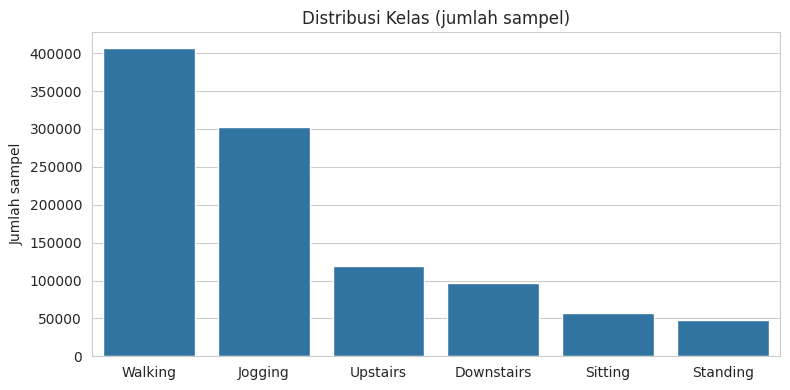

,Jumlah sampel,Persen (%),Durasi (menit)
activity,,,
Walking,407212,39.51,339.3
Jogging,302830,29.38,252.4
Upstairs,118838,11.53,99.0
Downstairs,97307,9.44,81.1
Sitting,57221,5.55,47.7
Standing,47228,4.58,39.4


Rasio kelas terbesar : terkecil = 8.62


In [ ]:
urutan = df["activity"].value_counts().index

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="activity", order=urutan)
plt.title("Distribusi Kelas (jumlah sampel)")
plt.xlabel("")
plt.ylabel("Jumlah sampel")
plt.tight_layout()
plt.savefig(f"{HASIL}/distribusi_kelas.png", dpi=150)
plt.show()

dist = pd.DataFrame({
    "Jumlah sampel": df["activity"].value_counts(),
    "Persen (%)": (df["activity"].value_counts(normalize=True) * 100).round(2),
    "Durasi (menit)": (df["activity"].value_counts() / FS / 60).round(1),
})
display(dist)
print("Rasio kelas terbesar : terkecil =", round(dist["Jumlah sampel"].max() / dist["Jumlah sampel"].min(), 2))

#### 8.1.2 Durasi rekaman per subjek per aktivitas (menit)

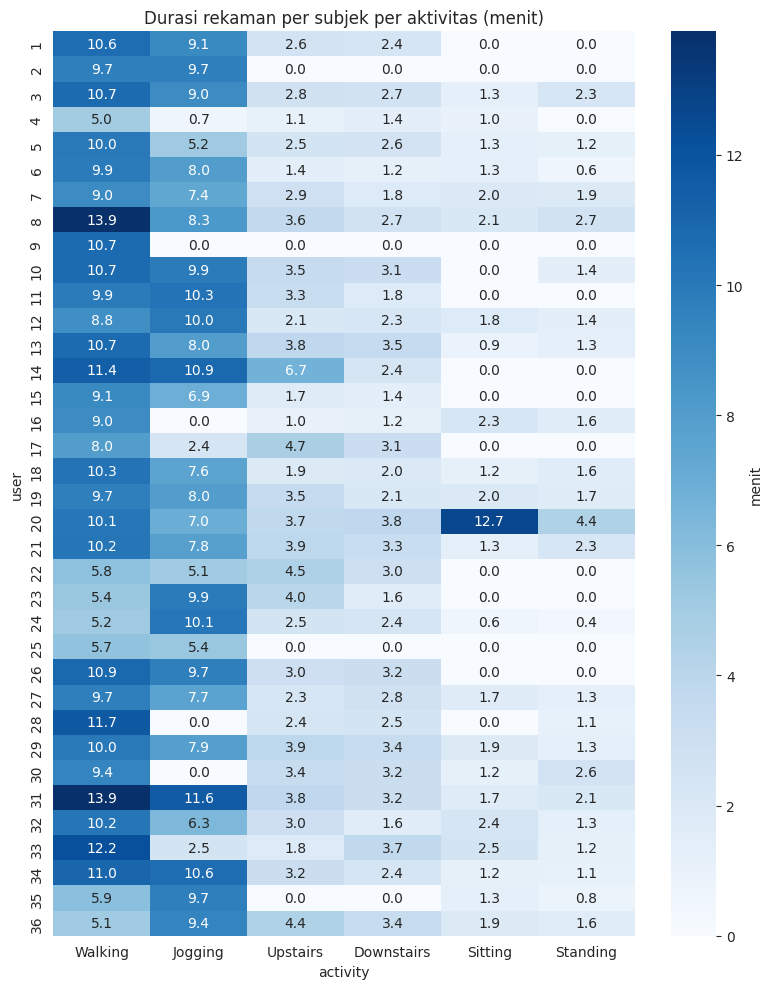

In [ ]:
cakupan = pd.crosstab(df["user"], df["activity"])[urutan] / FS / 60
n_akt = (cakupan > 0).sum(axis=1)

plt.figure(figsize=(8, 10))
sns.heatmap(cakupan.round(1), annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "menit"})
plt.title("Durasi rekaman per subjek per aktivitas (menit)")
plt.tight_layout()
plt.savefig(f"{HASIL}/cakupan_per_subjek.png", dpi=150)
plt.show()

#### 8.1.3 Ringkasan cakupan aktivitas per subjek

In [ ]:
print("Jumlah subjek berdasarkan banyak aktivitas yang direkam")
print(n_akt.value_counts().sort_index())

print("\nSubjek yang tidak merekam semua aktivitas")
display(cakupan[n_akt < 6].round(1))

print("Jumlah subjek yang merekam tiap aktivitas")
print((cakupan > 0).sum())

print("\nTotal durasi per subjek (menit)")
print(cakupan.sum(axis=1).describe().round(1))

Jumlah subjek berdasarkan banyak aktivitas yang direkam
1     1
2     2
4    10
5     4
6    19
Name: count, dtype: int64

Subjek yang tidak merekam semua aktivitas


activity,Walking,Jogging,Upstairs,Downstairs,Sitting,Standing
user,,,,,,
1,10.6,9.1,2.6,2.4,0.0,0.0
2,9.7,9.7,0.0,0.0,0.0,0.0
4,5.0,0.7,1.1,1.4,1.0,0.0
9,10.7,0.0,0.0,0.0,0.0,0.0
10,10.7,9.9,3.5,3.1,0.0,1.4
11,9.9,10.3,3.3,1.8,0.0,0.0
14,11.4,10.9,6.7,2.4,0.0,0.0
15,9.1,6.9,1.7,1.4,0.0,0.0
16,9.0,0.0,1.0,1.2,2.3,1.6


Jumlah subjek yang merekam tiap aktivitas
activity
Walking       36
Jogging       32
Upstairs      32
Downstairs    32
Sitting       23
Standing      24
dtype: int64

Total durasi per subjek (menit)
count    36.0
mean     23.9
std       6.9
min       9.3
25%      19.4
50%      24.8
75%      28.3
max      41.7
dtype: float64


#### 8.1.4 Hasil Distribusi Kelas dan Cakupan per Subjek

Kelas pada data ini tidak seimbang. Walking mencakup 39,51% data (339,3 menit) dan Jogging 29,38%, sedangkan Sitting hanya 5,55% dan Standing 4,58% (39,4 menit). Perbandingan kelas terbesar dengan kelas terkecil mencapai 8,62 kali. Karena itu, macro-F1 digunakan sebagai metrik utama, sebab akurasi akan didominasi oleh Walking dan Jogging.

Hanya 19 dari 36 subjek yang merekam keenam aktivitas. Sebanyak 10 subjek merekam 4 aktivitas, 4 subjek merekam 5 aktivitas, subjek 2 dan 25 hanya merekam Walking dan Jogging, dan subjek 9 hanya merekam Walking. Kelas statis memiliki subjek paling sedikit, yaitu 23 subjek untuk Sitting dan 24 subjek untuk Standing, sementara Walking direkam oleh seluruh 36 subjek. Durasi rekaman per subjek juga bervariasi, antara 9,3 dan 41,7 menit dengan rata-rata 23,9 menit.

Subjek 20 mendominasi kelas Sitting dengan durasi 12,7 menit, atau sekitar 27% dari seluruh data Sitting. Subjek lain umumnya hanya merekam Sitting selama 0,6 sampai 2,5 menit.

Kondisi ini membuat split per subjek tidak bisa dilakukan dengan pengacakan biasa. Dengan hanya 5 sampai 6 subjek di validasi dan test, pengacakan sederhana berisiko membuat Sitting atau Standing tidak muncul sama sekali di salah satu bagian. Karena itu, split dicari dengan mencoba banyak kombinasi subjek dan memilih kombinasi yang memastikan setiap kelas muncul dari minimal 2 subjek di setiap bagian, dengan proporsi kelas dan jumlah sampel yang paling mendekati 70/15/15. Posisi subjek 20 juga perlu diperhatikan, karena jika masuk ke test, skor Sitting sebagian besar hanya mencerminkan satu orang.

### 8.2 Keteraturan Waktu Sampling

#### 8.2.1 Statistik selisih waktu antarsampel (ms)

In [ ]:
dt_ms = (df.groupby(["user", "activity"])["timestamp"].diff() / 1e6).dropna()

print(dt_ms.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2))

batas = [0, 40, 60, 100, 200, 1000, 10_000, np.inf]
label = ["<40", "40-60 (normal)", "60-100", "100-200", "200 ms-1 dtk", "1-10 dtk", ">10 dtk"]
print("\nDistribusi selisih waktu")
print(pd.cut(dt_ms, bins=batas, labels=label, right=False).value_counts().sort_index())
print("\nSelisih negatif (timestamp mundur) =", (dt_ms < 0).sum())

count     1030457.00
mean          231.21
std         67238.38
min            35.19
1%             39.25
5%             39.92
25%            49.93
50%            49.99
75%            50.05
95%            80.14
99%           119.96
max      39190640.02
Name: timestamp, dtype: float64

Distribusi selisih waktu
timestamp
<40                87486
40-60 (normal)    823290
60-100             88397
100-200            26981
200 ms-1 dtk        4046
1-10 dtk              24
>10 dtk              233
Name: count, dtype: int64

Selisih negatif (timestamp mundur) = 0


#### 8.2.2 Histogram selisih waktu antarsampel

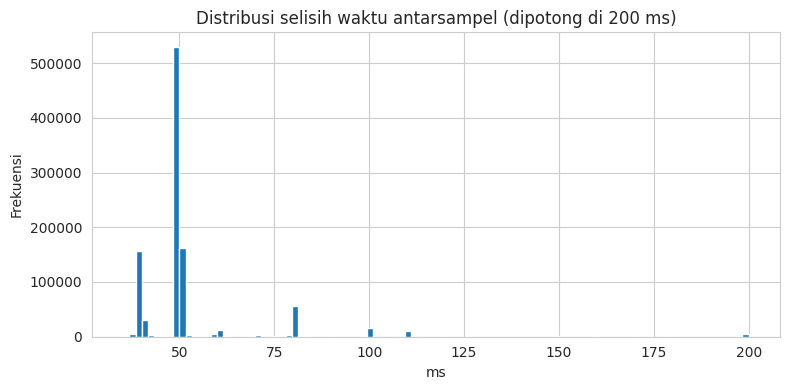

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(dt_ms.clip(0, 200), bins=100)
plt.title("Distribusi selisih waktu antarsampel (dipotong di 200 ms)")
plt.xlabel("ms")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.savefig(f"{HASIL}/selisih_waktu.png", dpi=150)
plt.show()

#### 8.2.3 Hasil keteraturan waktu sampling

Median selisih waktu antarsampel adalah 49,99 ms, sesuai dengan frekuensi 20 Hz pada dokumentasi. Meski begitu, sampling tidak sepenuhnya teratur. Hanya 79,9% selisih (823.290 dari 1.030.457) yang berada di rentang normal 40 sampai 60 ms. Histogram menunjukkan beberapa puncak, yaitu di sekitar 40 ms (87.486 selisih, setara sekitar 25 Hz), 50 ms (normal), serta 80, 100, dan 110 ms yang menandakan satu atau dua sampel terlewat. Pola seperti ini umum pada sensor smartphone, karena waktu pembacaan sensor diatur oleh sistem operasi.

Ada juga celah yang lebih besar, yaitu 4.046 celah antara 200 ms dan 1 detik, 24 celah antara 1 dan 10 detik, serta 233 celah lebih dari 10 detik. Celah terbesar sekitar 39.190 detik atau hampir 11 jam. Artinya, rekaman satu subjek untuk satu aktivitas bisa terdiri atas beberapa sesi terpisah, ditambah celah dari record yang dibuang saat pembersihan. Tidak ada timestamp yang mundur, jadi urutan data sudah benar.

Temuan ini berpengaruh langsung pada segmentasi. Sinyal tidak boleh dipotong setiap N sampel begitu saja, karena satu jendela bisa melompati celah berjam-jam dan menggabungkan dua sesi yang berbeda. Sebelum segmentasi, data dipecah dulu menjadi sesi kontinu di setiap titik yang selisih waktunya melewati ambang tertentu, dan nilai ambangnya ditentukan di bagian 10. Ketidakteraturan kecil seperti 40, 80, atau 100 ms tidak diperbaiki dengan resampling, jadi jendela dihitung berdasarkan jumlah sampel dengan asumsi 20 Hz. Keterbatasan ini dicatat di laporan.

### 8.3 Bentuk Sinyal, Sebaran Nilai, dan Korelasi Antarsumbu

#### 8.3.1 Contoh sinyal 10 detik tiap kelas

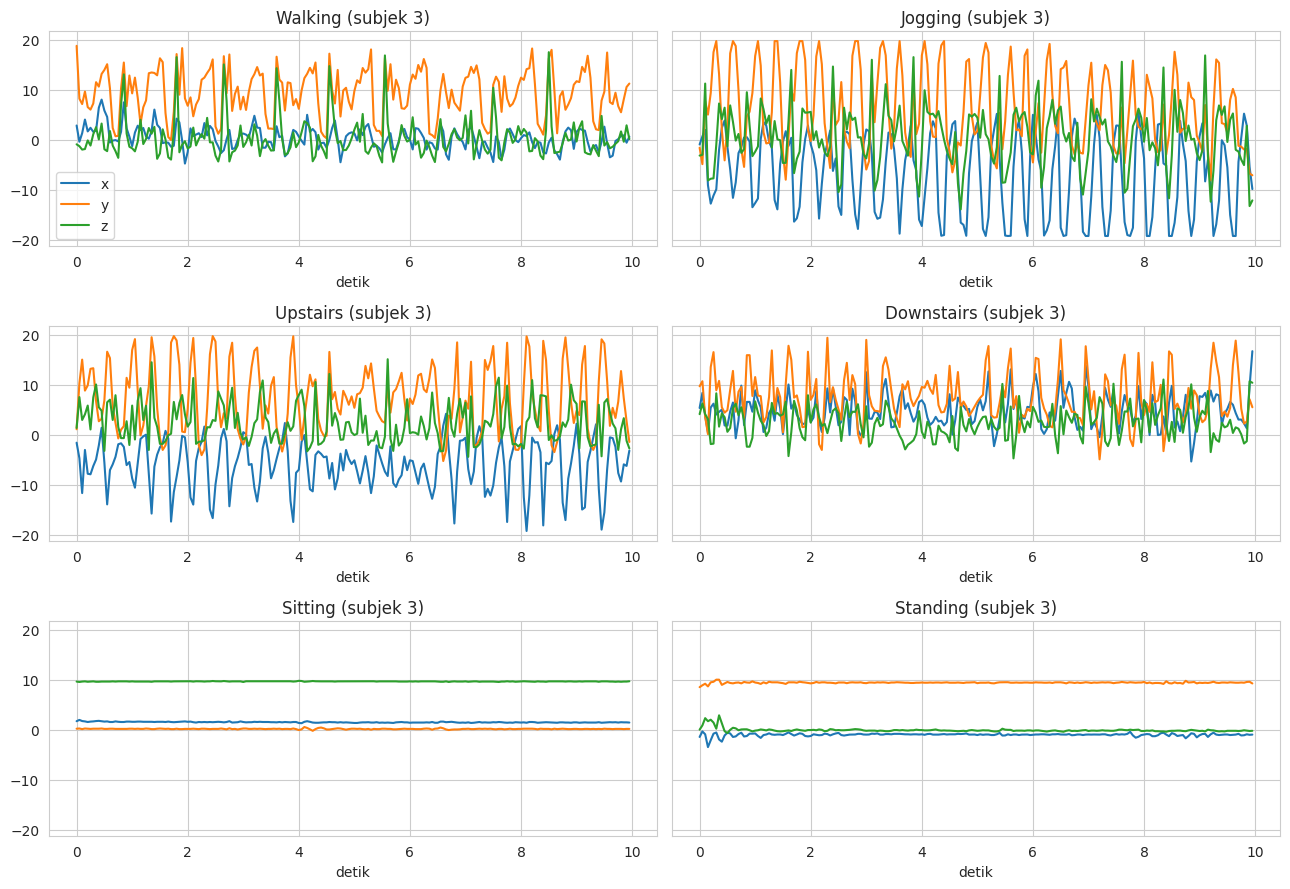

In [ ]:
subjek_contoh = n_akt[n_akt == 6].index[0]

fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharey=True)
for ax, akt in zip(axes.flat, urutan):
    s = df[(df.user == subjek_contoh) & (df.activity == akt)].iloc[:200]
    t = np.arange(len(s)) / FS
    for c in SUMBU:
        ax.plot(t, s[c], label=c)
    ax.set_title(f"{akt} (subjek {subjek_contoh})")
    ax.set_xlabel("detik")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig(f"{HASIL}/contoh_sinyal.png", dpi=150)
plt.show()

#### 8.3.2 Boxplot nilai per sumbu per aktivitas

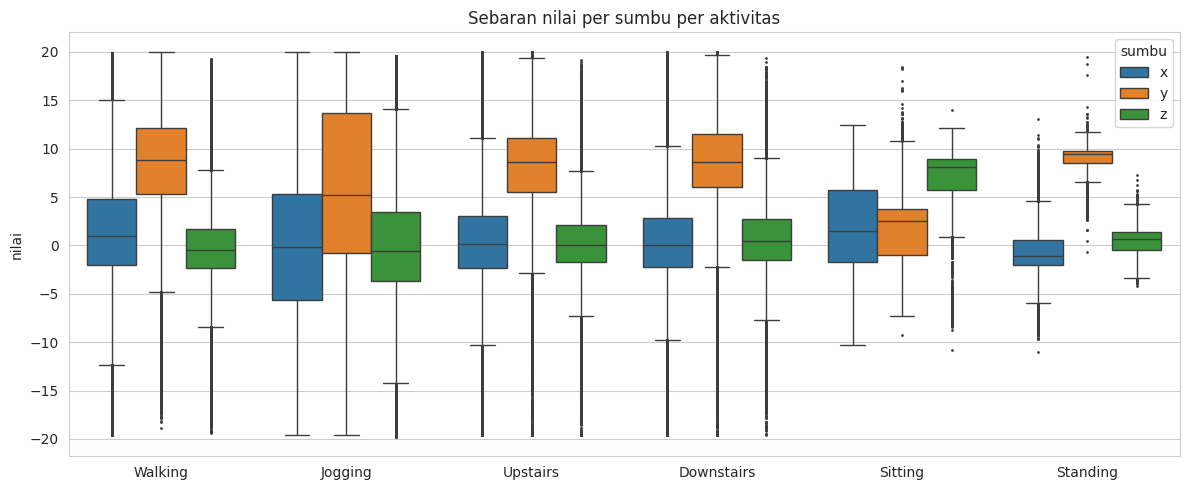

In [ ]:
df_long = df.melt(id_vars="activity", value_vars=SUMBU, var_name="sumbu", value_name="nilai")

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_long, x="activity", y="nilai", hue="sumbu", order=urutan, fliersize=1)
plt.title("Sebaran nilai per sumbu per aktivitas")
plt.xlabel("")
plt.tight_layout()
plt.savefig(f"{HASIL}/boxplot_aktivitas.png", dpi=150)
plt.show()

#### 8.3.3 Mean dan simpangan baku per aktivitas

In [ ]:
print("Mean per aktivitas")
display(df.groupby("activity")[SUMBU].mean().loc[urutan].round(2))

print("Simpangan baku per aktivitas")
display(df.groupby("activity")[SUMBU].std().loc[urutan].round(2))

Mean per aktivitas


,x,y,z
activity,,,
Walking,1.54,8.75,-0.08
Jogging,-0.21,5.71,-0.15
Upstairs,0.36,8.14,0.31
Downstairs,0.44,8.65,0.68
Sitting,1.82,1.88,6.56
Standing,-1.18,8.98,0.58


Simpangan baku per aktivitas


,x,y,z
activity,,,
Walking,5.73,4.95,4.01
Jogging,9.16,9.33,5.97
Upstairs,5.51,4.87,3.57
Downstairs,4.95,4.86,3.71
Sitting,4.76,3.27,3.74
Standing,3.24,1.27,1.38


#### 8.3.4 Persentase titik di luar pagar IQR (hanya diamati, tidak dibuang)

In [ ]:
def persen_luar_iqr(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

display(df.groupby("activity")[SUMBU].agg(persen_luar_iqr).loc[urutan].round(2))

,x,y,z
activity,,,
Walking,2.88,0.73,6.17
Jogging,0.00,0.00,2.63
Upstairs,6.49,2.80,5.10
Downstairs,6.20,2.10,3.66
Sitting,0.00,0.14,5.19
Standing,12.69,8.36,0.08


#### 8.3.5 Korelasi antarsumbu per aktivitas

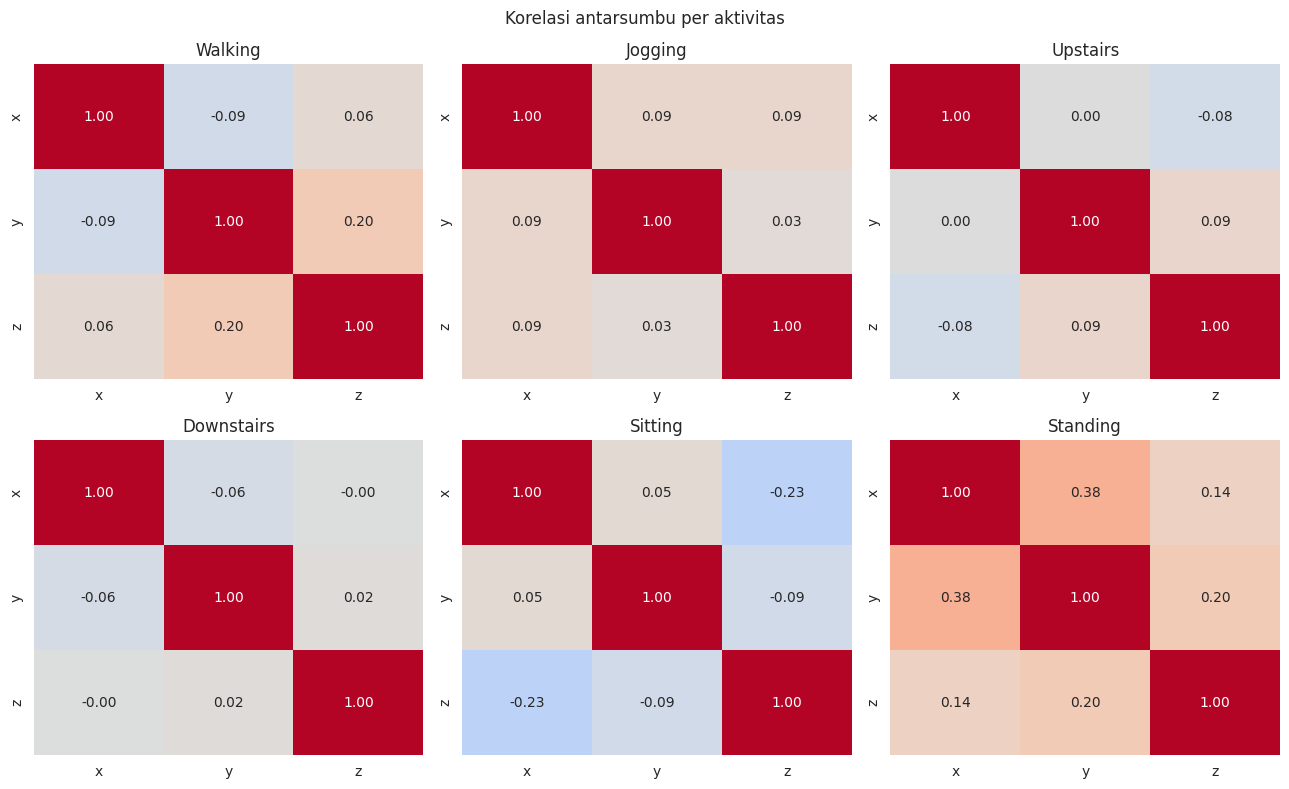

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, akt in zip(axes.flat, urutan):
    sns.heatmap(df[df.activity == akt][SUMBU].corr(), annot=True, fmt=".2f",
                vmin=-1, vmax=1, cmap="coolwarm", ax=ax, cbar=False)
    ax.set_title(akt)
plt.suptitle("Korelasi antarsumbu per aktivitas")
plt.tight_layout()
plt.savefig(f"{HASIL}/korelasi_sumbu.png", dpi=150)
plt.show()

#### 8.3.6 Hasil

Walking, Jogging, Upstairs, dan Downstairs menghasilkan sinyal periodik. Jogging memiliki amplitudo dan simpangan baku terbesar (x = 9,16 dan y = 9,33) serta siklus yang paling rapat. Pada plot contoh sinyal, puncak Jogging terlihat terpotong rata di sekitar ±20, yang menguatkan temuan saturasi sensor di bagian 7.

Sitting dan Standing menghasilkan sinyal yang hampir datar, dan keduanya terutama dibedakan oleh arah gravitasi. Saat Sitting, gravitasi dominan di sumbu z (mean z = 6,56), sedangkan saat Standing gravitasi dominan di sumbu y (mean y = 8,98). Orientasi ponsel menjadi informasi kunci untuk membedakan kedua kelas ini.

Upstairs dan Downstairs sangat mirip. Mean sumbu y keduanya 8,14 dan 8,65, simpangan bakunya 4,87 dan 4,86, dan keduanya juga mirip dengan Walking. Ketiga kelas ini kemungkinan paling sering tertukar.

Simpangan baku Sitting cukup besar (x = 4,76) meskipun sinyalnya datar. Variasi ini kemungkinan berasal dari perbedaan posisi ponsel antarsubjek, bukan dari gerakan. Statistik yang dihitung dari gabungan semua subjek mencampur variasi antarsubjek dengan variasi di dalam rekaman.

Persentase titik di luar pagar IQR tidak menunjukkan kesalahan data. Standing justru memiliki persentase tertinggi (x = 12,69%) karena sebarannya sangat sempit, sehingga gerakan kecil pun sudah tergolong outlier. Sebaliknya, Jogging bernilai 0% karena sebarannya sangat lebar. Hasil ini menguatkan keputusan untuk tidak membuang outlier dengan metode IQR.

Korelasi antarsumbu lemah pada semua aktivitas, dengan nilai mutlak paling tinggi 0,38 (sumbu x dan y pada Standing), disusul −0,23 (sumbu x dan z pada Sitting). Ketiga sumbu membawa informasi yang relatif berbeda, sehingga semuanya dipertahankan.

Berdasarkan temuan ini, komponen gravitasi tidak dibuang (tidak dilakukan high-pass filter), karena mean per sumbu adalah pembeda utama Sitting dan Standing. Fitur yang direncanakan meliputi fitur domain waktu seperti mean, simpangan baku, nilai minimum dan maksimum, RMS, serta magnitudo resultan untuk menangkap orientasi dan intensitas, ditambah fitur domain frekuensi seperti frekuensi dominan dan energi spektral untuk membedakan ritme Walking, Upstairs, dan Downstairs. Korelasi antarfitur dianalisis lagi setelah ekstraksi fitur, dan hanya menggunakan data train.

Semua pola di atas bersifat eksploratif karena ditemukan setelah melihat data. Pola-pola ini diperlakukan sebagai dugaan yang diuji pada tahap pemodelan, bukan sebagai kesimpulan akhir.

## 9. Split Data per Subjek

Data dibagi per subjek, bukan per sampel atau per jendela, agar data dari satu orang tidak muncul sekaligus di train dan test. Jika hal itu terjadi, model bisa menghafal gaya gerak orang tersebut dan kinerjanya akan terlihat lebih tinggi dari kenyataan.

Karena cakupan aktivitas antarsubjek tidak sama (bagian 8.1), split dicari dengan mencoba 20.000 kombinasi subjek secara acak dengan seed tetap. Kombinasi yang dipilih harus memenuhi syarat bahwa setiap kelas muncul dari minimal 2 subjek di train, validasi, dan test. Di antara kombinasi yang memenuhi syarat, dipilih yang proporsi kelasnya paling mirip dengan proporsi keseluruhan dan jumlah sampelnya paling dekat dengan 70/15/15. Subjek dibagi menjadi 25 untuk train, 5 untuk validasi, dan 6 untuk test.

### 9.1 Pencarian Kombinasi Subjek

#### 9.1.1 Fungsi pencarian split per subjek

In [ ]:
def cari_split(df, n_test=6, n_val=5, n_iter=20_000, min_subjek=2, target=(0.70, 0.15, 0.15), seed=SEED):
    tab = pd.crosstab(df["user"], df["activity"])
    M = tab.to_numpy()
    users = tab.index.to_numpy()
    prop_all = M.sum(axis=0) / M.sum()

    rng = np.random.default_rng(seed)
    terbaik, n_valid = None, 0
    for _ in range(n_iter):
        idx = rng.permutation(len(users))
        bagian = [idx[n_test + n_val:], idx[n_test:n_test + n_val], idx[:n_test]]
        sub = [M[b] for b in bagian]

        if any(((s > 0).sum(axis=0) < min_subjek).any() for s in sub):
            continue
        n_valid += 1

        skor_kelas = sum(np.abs(s.sum(axis=0) / s.sum() - prop_all).sum() for s in sub)
        rasio = np.array([s.sum() for s in sub]) / M.sum()
        skor = skor_kelas + np.abs(rasio - np.array(target)).sum()

        if terbaik is None or skor < terbaik[0]:
            terbaik = (skor, [sorted(users[b].tolist()) for b in bagian])

    return terbaik, n_valid, tab

#### 9.1.2 Menjalankan pencarian dan terapkan split

In [ ]:
(skor, (train_users, val_users, test_users)), n_valid, tab = cari_split(df)

print(f"Kombinasi yang memenuhi syarat = {n_valid} dari 20000")
print(f"Skor terbaik = {skor:.4f}")
print("Subjek train =", train_users)
print("Subjek val   =", val_users)
print("Subjek test  =", test_users)

assert not (set(train_users) & set(val_users) or set(train_users) & set(test_users)
            or set(val_users) & set(test_users)), "Ada subjek yang tumpang tindih!"

df_train = df[df.user.isin(train_users)].reset_index(drop=True)
df_val   = df[df.user.isin(val_users)].reset_index(drop=True)
df_test  = df[df.user.isin(test_users)].reset_index(drop=True)

# Simpan identitas subjek per bagian
pd.DataFrame({"user": train_users + val_users + test_users,
              "bagian": ["train"] * len(train_users) + ["val"] * len(val_users) + ["test"] * len(test_users)}) \
  .to_csv(f"{HASIL}/pembagian_subjek.csv", index=False)

Kombinasi yang memenuhi syarat = 18516 dari 20000
Skor terbaik = 0.0940
Subjek train = [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 14, 17, 18, 20, 23, 25, 26, 28, 30, 31, 32, 33, 34, 35, 36]
Subjek val   = [9, 13, 21, 24, 29]
Subjek test  = [12, 15, 16, 19, 22, 27]


### 9.2 Ringkasan Hasil Split

#### 9.2.1 Jumlah subjek dan sampel per bagian

In [ ]:
ringkas_split = pd.DataFrame({
    "Subjek": [len(train_users), len(val_users), len(test_users)],
    "Sampel": [len(df_train), len(df_val), len(df_test)],
}, index=["Train", "Val", "Test"])
ringkas_split["% sampel"] = (ringkas_split["Sampel"] / len(df) * 100).round(2)
display(ringkas_split)

,Subjek,Sampel,% sampel
Train,25,732109,71.03
Val,5,140631,13.65
Test,6,157896,15.32


9.2.2 Proporsi kelas per bagian (%)

In [ ]:
prop = pd.DataFrame({
    "Keseluruhan": df.activity.value_counts(normalize=True),
    "Train": df_train.activity.value_counts(normalize=True),
    "Val": df_val.activity.value_counts(normalize=True),
    "Test": df_test.activity.value_counts(normalize=True),
}).loc[urutan] * 100
display(prop.round(2))

,Keseluruhan,Train,Val,Test
activity,,,,
Walking,39.51,39.42,39.86,39.61
Jogging,29.38,29.62,28.87,28.74
Upstairs,11.53,11.46,12.03,11.42
Downstairs,9.44,9.14,10.70,9.71
Sitting,5.55,5.77,3.95,5.95
Standing,4.58,4.58,4.60,4.57


#### 9.2.3 Jumlah subjek per kelas per bagian


In [ ]:
display(pd.DataFrame({
    "Train": (tab.loc[train_users] > 0).sum(),
    "Val": (tab.loc[val_users] > 0).sum(),
    "Test": (tab.loc[test_users] > 0).sum(),
}).loc[urutan])

bagian_s20 = "Train" if 20 in train_users else "Val" if 20 in val_users else "Test"
print("Subjek 20 (dominan di Sitting) berada di", bagian_s20)

,Train,Val,Test
activity,,,
Walking,25,5,6
Jogging,23,4,5
Upstairs,22,4,6
Downstairs,22,4,6
Sitting,15,4,4
Standing,16,4,4


Subjek 20 (dominan di Sitting) berada di Train


### 9.3 Hasil

Dari 20.000 kombinasi acak, 18.516 kombinasi (92,6%) memenuhi syarat. Syarat minimal 2 subjek per kelas ternyata tidak terlalu ketat, sehingga kombinasi yang terpilih tidak dipaksakan dari sedikit pilihan.

| Bagian | Subjek | Jumlah sampel | Persentase |
|---|---|---|---|
| Train | 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 14, 17, 18, 20, 23, 25, 26, 28, 30, 31, 32, 33, 34, 35, 36 | 732.109 | 71,03% |
| Validasi | 9, 13, 21, 24, 29 | 140.631 | 13,65% |
| Test | 12, 15, 16, 19, 22, 27 | 157.896 | 15,32% |

Rasio sampel 71/14/15 cukup dekat dengan target 70/15/15. Rasio tidak bisa tepat karena yang dibagi adalah subjek, sedangkan durasi rekaman setiap subjek berbeda.

Proporsi kelas di ketiga bagian sangat mirip dengan proporsi keseluruhan, dengan selisih paling besar sekitar 1,6 poin persen. Selisih terbesar ada pada Sitting di validasi (3,95% dibanding 5,55% secara keseluruhan) dan Downstairs di validasi (10,70% dibanding 9,44%). Setiap kelas di validasi dan test berasal dari minimal 4 subjek. Subjek 20, yang mendominasi kelas Sitting, masuk ke train, sehingga skor Sitting di test tidak bergantung pada satu orang tersebut. Subjek 9 yang hanya merekam Walking masuk ke validasi, dan hal ini tidak menjadi masalah karena kelas lain di validasi tetap diwakili subjek lain.

Mulai tahap ini, semua parameter yang dipelajari dari data, seperti normalisasi dan bobot kelas, hanya dihitung dari train. Segmentasi juga dilakukan setelah split dan terpisah untuk setiap bagian, sehingga tidak ada jendela yang berisi data dari dua bagian berbeda. Daftar subjek per bagian disimpan di `hasil/pembagian_subjek.csv`.

## 10. Segmentasi

Sinyal kontinu dipotong menjadi jendela berukuran tetap, dan setiap jendela menjadi satu sampel untuk klasifikasi. Segmentasi dilakukan terpisah untuk train, validasi, dan test. Sebelum dipotong, data dipecah dulu menjadi sesi kontinu per subjek dan aktivitas di setiap titik yang selisih waktunya melewati ambang tertentu (bagian 8.2), agar satu jendela tidak melompati celah. Karena setiap jendela hanya berasal dari satu sesi, labelnya pasti tunggal. Jendela yang tidak penuh di akhir sesi dibuang.

### 10.1 Fungsi Segmentasi

In [ ]:
def tandai_sesi(data, ambang_ms):
    data = data.sort_values(["user", "activity", "timestamp"]).reset_index(drop=True)
    dt = data.groupby(["user", "activity"])["timestamp"].diff() / 1e6
    data["sesi"] = (dt.isna() | (dt > ambang_ms)).cumsum()
    return data

def hitung_jendela(data, win, step):
    ukuran = data.groupby(["sesi", "activity"]).size().reset_index(name="n")
    ukuran["n_win"] = np.where(ukuran.n >= win, (ukuran.n - win) // step + 1, 0)
    ukuran["terpakai"] = np.where(ukuran.n_win > 0, (ukuran.n_win - 1) * step + win, 0)
    return ukuran

def segmentasi(data, win, step, ambang_ms):
    data = tandai_sesi(data, ambang_ms)
    X, y, subjek, sesi, celah_maks, durasi = [], [], [], [], [], []
    for sid, s in data.groupby("sesi", sort=False):
        if len(s) < win:
            continue
        nilai = s[SUMBU].to_numpy(dtype=np.float32)
        ts = s["timestamp"].to_numpy()
        for mulai in range(0, len(s) - win + 1, step):
            t_win = ts[mulai:mulai + win]
            X.append(nilai[mulai:mulai + win])
            y.append(s["activity"].iat[0])
            subjek.append(s["user"].iat[0])
            sesi.append(sid)
            celah_maks.append(np.diff(t_win).max() / 1e6)
            durasi.append((t_win[-1] - t_win[0]) / 1e9)
    return (np.stack(X), np.array(y), np.array(subjek), np.array(sesi),
            np.array(celah_maks), np.array(durasi))

#### 10.2.1 Hasil perbandingan parameter

Dua parameter dibandingkan sebelum segmentasi final. Yang pertama adalah ambang celah untuk memecah sesi, yaitu 200 ms atau 1 detik. Yang kedua adalah panjang jendela, yaitu 128 sampel (6,4 detik) yang umum dipakai di penelitian HAR, atau 200 sampel (10 detik) yang dipakai pada paper asli WISDM. Overlap ditetapkan 50%.

In [ ]:
hasil_param, per_kelas = [], {}
for ambang in [200, 1000]:
    for win in [128, 200]:
        step = win // 2
        for nama, d in [("Train", df_train), ("Val", df_val), ("Test", df_test)]:
            ds = tandai_sesi(d, ambang)
            u = hitung_jendela(ds, win, step)
            hasil_param.append({
                "Ambang (ms)": ambang, "Window": win, "Bagian": nama,
                "Jumlah sesi": ds.sesi.nunique(),
                "Sesi < 1 jendela": int((u.n < win).sum()),
                "Jumlah jendela": int(u.n_win.sum()),
                "% sampel terpakai": round(u.terpakai.sum() / len(ds) * 100, 2),
            })
            per_kelas[(ambang, win, nama)] = u.groupby("activity").n_win.sum()

display(pd.DataFrame(hasil_param))

,Ambang (ms),Window,Bagian,Jumlah sesi,Sesi < 1 jendela,Jumlah jendela,% sampel terpakai
0,200,128,Train,2902,2458,10070,91.91
1,200,128,Val,639,523,1743,84.60
2,200,128,Test,941,787,1900,83.25
3,200,200,Train,2902,2503,6200,90.14
4,200,200,Val,639,547,1043,80.71
5,200,200,Test,941,830,1126,78.34
6,1000,128,Train,296,9,11006,98.72
7,1000,128,Val,57,0,2114,98.80
8,1000,128,Test,83,3,2342,98.17
9,1000,200,Train,296,16,6886,97.88


In [ ]:
kelas_param = pd.DataFrame(per_kelas).loc[urutan]
kelas_param.columns = [f"{a}ms|w{w}|{b}" for a, w, b in kelas_param.columns]
display(kelas_param)

,200ms|w128|Train,200ms|w128|Val,200ms|w128|Test,200ms|w200|Train,200ms|w200|Val,200ms|w200|Test,1000ms|w128|Train,1000ms|w128|Val,1000ms|w128|Test,1000ms|w200|Train,1000ms|w200|Val,1000ms|w200|Test
activity,,,,,,,,,,,,
Walking,4304,831,883,2700,511,542,4435,861,962,2815,545,613
Jogging,2605,328,401,1610,190,238,3310,623,696,2084,394,442
Upstairs,1159,227,200,681,133,106,1189,240,240,716,144,135
Downstairs,881,183,178,515,103,95,933,213,197,558,126,112
Sitting,624,78,131,385,47,79,638,81,140,400,50,89
Standing,497,96,107,309,59,66,501,96,107,313,59,66


Ambang 200 ms memecah data terlalu halus. Data train terpecah menjadi 2.902 sesi, dan 2.458 di antaranya (85%) lebih pendek dari satu jendela sehingga terbuang. Data yang terpakai hanya 78 sampai 92%, dan paling rendah pada test dengan jendela 200 (78,34%). Kelas yang paling dirugikan adalah Jogging. Pada validasi dengan jendela 128, jumlah jendela Jogging hanya 328 dengan ambang 200 ms, dibanding 623 dengan ambang 1 detik, sehingga sekitar 47% hilang. Hal ini sesuai dengan temuan di bagian 7, yaitu rekaman Jogging paling banyak memiliki record rusak sehingga paling banyak meninggalkan celah setelah pembersihan.

Ambang 1 detik mempertahankan 96 sampai 99% data, dengan jumlah sesi yang wajar (296 di train, 57 di validasi, dan 83 di test) dan hanya 0 sampai 21 sesi yang terlalu pendek. Jendela 128 menghasilkan sekitar 60% lebih banyak jendela daripada jendela 200 (11.006 dibanding 6.886 di train). Kelas terkecil di validasi juga lebih terwakili, misalnya Sitting dengan 81 jendela dibanding 50 dan Standing dengan 96 jendela dibanding 59.

Berdasarkan hasil ini, ambang celah ditetapkan 1 detik. Ambang 200 ms membuang data secara tidak merata dan merugikan Jogging, sehingga distribusi kelas di validasi dan test ikut berubah. Konsekuensinya, sebagian jendela masih bisa memuat celah kecil di bawah 1 detik, dan dampaknya diukur di bagian 10.3.

Panjang jendela ditetapkan 128 sampel (6,4 detik) dengan overlap 50% (step 64). Pada 20 Hz, durasi 6,4 detik masih memuat banyak siklus langkah, sehingga pola periodik tetap tertangkap. Jumlah jendela yang lebih banyak juga membantu pelatihan 1D-CNN dan membuat evaluasi kelas kecil lebih stabil. Perlu dicatat bahwa jendela yang overlap 50% tidak saling independen, sehingga jumlah jendela yang lebih banyak tidak berarti informasi baru sebanyak itu. Satuan yang benar-benar independen tetap subjek.

#### 10.3.1 Hasil segmentasi final

Parameter final adalah ambang celah 1 detik, panjang jendela 128 sampel (6,4 detik), dan overlap 50% (step 64). Setiap jendela menyimpan sinyal berukuran 128 × 3, label, ID subjek, ID sesi, celah waktu terbesar di dalamnya, dan durasi nyatanya.

In [ ]:
AMBANG_MS = 1000
WIN = 128
STEP = WIN // 2      # overlap 50%

X_train, y_train_txt, g_train, s_train, c_train, d_train = segmentasi(df_train, WIN, STEP, AMBANG_MS)
X_val,   y_val_txt,   g_val,   s_val,   c_val,   d_val   = segmentasi(df_val,   WIN, STEP, AMBANG_MS)
X_test,  y_test_txt,  g_test,  s_test,  c_test,  d_test  = segmentasi(df_test,  WIN, STEP, AMBANG_MS)

print("Shape X_train =", X_train.shape)
print("Shape X_val   =", X_val.shape)
print("Shape X_test  =", X_test.shape)

assert not (set(g_train) & set(g_val) or set(g_train) & set(g_test) or set(g_val) & set(g_test)), \
    "Ada subjek yang muncul di lebih dari satu bagian"

Shape X_train = (11006, 128, 3)
Shape X_val   = (2114, 128, 3)
Shape X_test  = (2342, 128, 3)


In [ ]:
dist_win = pd.DataFrame({
    "Train": pd.Series(y_train_txt).value_counts(),
    "Val": pd.Series(y_val_txt).value_counts(),
    "Test": pd.Series(y_test_txt).value_counts(),
}).loc[urutan]
dist_win["Train %"] = (dist_win["Train"] / dist_win["Train"].sum() * 100).round(2)
display(dist_win)

,Train,Val,Test,Train %
activity,,,,
Walking,4435,861,962,40.30
Jogging,3310,623,696,30.07
Upstairs,1189,240,240,10.80
Downstairs,933,213,197,8.48
Sitting,638,81,140,5.80
Standing,501,96,107,4.55


In [ ]:
kualitas = pd.DataFrame({
    nama: {
        "Median celah maks (ms)": np.median(c).round(1),
        "% jendela celah > 200 ms": round((c > 200).mean() * 100, 2),
        "% jendela celah > 500 ms": round((c > 500).mean() * 100, 2),
        "Median durasi (dtk)": np.median(d).round(2),
        "Durasi min (dtk)": d.min().round(2),
        "Durasi maks (dtk)": d.max().round(2),
    }
    for nama, c, d in [("Train", c_train, d_train), ("Val", c_val, d_val), ("Test", c_test, d_test)]
}).T
display(kualitas)

,Median celah maks (ms),% jendela celah > 200 ms,% jendela celah > 500 ms,Median durasi (dtk),Durasi min (dtk),Durasi maks (dtk)
Train,102.3,9.46,0.64,6.45,6.32,19.36
Val,119.8,19.30,0.47,6.46,6.32,10.07
Test,119.8,20.96,0.47,6.48,6.32,12.54


In [ ]:
le = LabelEncoder().fit(y_train_txt)
y_train = le.transform(y_train_txt)
y_val   = le.transform(y_val_txt)
y_test  = le.transform(y_test_txt)
kelas = le.classes_
print("Mapping label =", dict(zip(kelas, le.transform(kelas))))

Mapping label = {np.str_('Downstairs'): np.int64(0), np.str_('Jogging'): np.int64(1), np.str_('Sitting'): np.int64(2), np.str_('Standing'): np.int64(3), np.str_('Upstairs'): np.int64(4), np.str_('Walking'): np.int64(5)}


Segmentasi menghasilkan 11.006 jendela train, 2.114 jendela validasi, dan 2.342 jendela test, masing-masing berukuran 128 sampel × 3 sumbu. Tidak ada subjek yang muncul di lebih dari satu bagian. Distribusi kelas pada level jendela tetap mirip dengan level sampel. Di train, Walking mencakup 40,30%, Jogging 30,07%, Upstairs 10,80%, Downstairs 8,48%, Sitting 5,80%, dan Standing 4,55%. Kelas paling kecil adalah Sitting di validasi (81 jendela) dan Standing di test (107 jendela).

Durasi nyata jendela sesuai dengan durasi nominalnya. Median durasi 6,45 sampai 6,48 detik, mendekati 128 / 20 Hz = 6,4 detik. Durasi terpendek 6,32 detik berasal dari bagian dengan sampling sedikit lebih cepat. Jendela terpanjang di train mencapai 19,36 detik, yang menunjukkan sebagian kecil rekaman memiliki sampling jauh lebih lambat dari 20 Hz.

Jendela yang memuat celah lebih dari 500 ms hanya 0,47 sampai 0,64%, sehingga dampak ambang 1 detik kecil. Namun jendela dengan celah lebih dari 200 ms dua kali lebih banyak di validasi (19,30%) dan test (20,96%) dibanding train (9,46%). Kualitas sampling di validasi dan test sedikit lebih buruk daripada di train. Karena sinyal tidak diresampling, fitur frekuensi pada jendela yang samplingnya tidak teratur menjadi sedikit kurang akurat. Perbedaan kualitas ini juga dicatat sebagai salah satu kemungkinan penyebab jika kinerja di test lebih rendah daripada di train, selain perbedaan antarsubjek.

Label diubah menjadi angka dengan LabelEncoder yang di-fit pada train, dengan urutan Downstairs = 0, Jogging = 1, Sitting = 2, Standing = 3, Upstairs = 4, dan Walking = 5.

## 11. Ekstraksi Fitur

Fitur dihitung per jendela pada empat kanal, yaitu sumbu x, y, z, dan magnitudo √(x² + y² + z²). Magnitudo tidak bergantung pada orientasi ponsel, sehingga melengkapi sumbu individual yang membawa informasi orientasi, yang penting untuk membedakan Sitting dan Standing (bagian 8.3).

| Kelompok | Fitur | Yang ditangkap |
|---|---|---|
| Domain waktu, posisi | mean, median, min, max | orientasi dan gravitasi |
| Domain waktu, sebaran | simpangan baku, IQR, RMS, rata-rata selisih absolut | intensitas gerakan |
| Domain waktu, bentuk | skewness, kurtosis, zero-crossing rate | asimetri dan ketajaman puncak |
| Domain frekuensi | frekuensi dominan, energi spektral, entropi spektral | ritme dan kecepatan langkah |
| Domain frekuensi, pita | proporsi energi pada pita 0–1, 1–2, 2–3, 3–5, dan 5–10 Hz | sebaran energi gerakan |
| Antarsumbu | korelasi x dan y, x dan z, y dan z | hubungan gerak antarsumbu |

Setiap kanal menghasilkan 19 fitur, sehingga empat kanal menghasilkan 76 fitur, ditambah 3 fitur korelasi antarsumbu. Totalnya 79 fitur. Frekuensi Nyquist adalah 10 Hz dan resolusi frekuensinya 20/128 = 0,156 Hz. Komponen DC (mean) dibuang sebelum FFT, supaya frekuensi dominan tidak selalu 0 Hz akibat gravitasi.

Fitur dihitung terpisah untuk train, validasi, dan test. Ekstraksi fitur tidak mempelajari parameter dari data karena setiap jendela dihitung sendiri, sehingga tidak ada kebocoran. Normalisasi baru dilakukan di tahap pemodelan dan hanya di-fit pada train.

### 11.1 Fungsi Ekstraksi Fitur

#### 11.1.1 Fitur per kanal (domain waktu dan frekuensi)

In [ ]:
FREQ = rfftfreq(WIN, d=1 / FS)
PITA = [(0, 1), (1, 2), (2, 3), (3, 5), (5, 10)]

def fitur_kanal(sig):
    """sig berbentuk (n_jendela, WIN) untuk satu kanal."""
    f = {}
    mean = sig.mean(axis=1)

    # Domain waktu
    f["mean"] = mean
    f["std"] = sig.std(axis=1)
    f["min"] = sig.min(axis=1)
    f["max"] = sig.max(axis=1)
    f["median"] = np.median(sig, axis=1)
    q75, q25 = np.percentile(sig, [75, 25], axis=1)
    f["iqr"] = q75 - q25
    f["rms"] = np.sqrt((sig ** 2).mean(axis=1))
    f["skew"] = skew(sig, axis=1)
    f["kurt"] = kurtosis(sig, axis=1)
    f["mad_diff"] = np.abs(np.diff(sig, axis=1)).mean(axis=1)
    pusat = sig - mean[:, None]
    f["zcr"] = (np.diff(np.sign(pusat), axis=1) != 0).mean(axis=1)

    # Domain frekuensi (komponen DC dibuang)
    spek = np.abs(rfft(pusat, axis=1)) ** 2
    total = spek[:, 1:].sum(axis=1) + 1e-12
    f["dom_freq"] = FREQ[1:][spek[:, 1:].argmax(axis=1)]
    f["spec_energy"] = total / WIN
    p = spek[:, 1:] / total[:, None]
    f["spec_entropy"] = -(p * np.log2(p + 1e-12)).sum(axis=1) / np.log2(p.shape[1])
    for a, b in PITA:
        m = (FREQ >= a) & (FREQ < b) & (FREQ > 0)
        f[f"band_{a}_{b}Hz"] = spek[:, m].sum(axis=1) / total
    return f

#### 11.1.2 Ekstraksi fitur untuk semua kanal dan korelasi antarsumbu


In [ ]:
def ekstraksi_fitur(X):
    kanal = {"x": X[:, :, 0], "y": X[:, :, 1], "z": X[:, :, 2],
             "mag": np.sqrt((X ** 2).sum(axis=2))}
    kolom = {}
    for nama, sig in kanal.items():
        for k, v in fitur_kanal(sig).items():
            kolom[f"{nama}_{k}"] = v

    # Korelasi antarsumbu per jendela (0 jika salah satu sinyal konstan)
    for a, b in [("x", "y"), ("x", "z"), ("y", "z")]:
        sa = kanal[a] - kanal[a].mean(axis=1, keepdims=True)
        sb = kanal[b] - kanal[b].mean(axis=1, keepdims=True)
        den = np.sqrt((sa ** 2).sum(axis=1) * (sb ** 2).sum(axis=1))
        kolom[f"corr_{a}{b}"] = np.where(den > 0, (sa * sb).sum(axis=1) / np.where(den > 0, den, 1), 0.0)
    return pd.DataFrame(kolom)

### 11.2 Hasil Ekstraksi

#### 11.2.1 Ekstraksi fitur train, validasi, dan test

In [ ]:
t0 = time.time()
F_train = ekstraksi_fitur(X_train)
F_val   = ekstraksi_fitur(X_val)
F_test  = ekstraksi_fitur(X_test)
print(f"Waktu ekstraksi = {time.time() - t0:.2f} detik")
print("Shape F_train =", F_train.shape)
print("Shape F_val   =", F_val.shape)
print("Shape F_test  =", F_test.shape)

for nama, F in [("Train", F_train), ("Val", F_val), ("Test", F_test)]:
    print(f"{nama}, NaN = {F.isna().sum().sum()}, Inf = {np.isinf(F.to_numpy()).sum()}")
print("Fitur dengan std = 0 di train =", list(F_train.columns[F_train.std() == 0]))

Waktu ekstraksi = 0.68 detik
Shape F_train = (11006, 79)
Shape F_val   = (2114, 79)
Shape F_test  = (2342, 79)
Train, NaN = 0, Inf = 0
Val, NaN = 0, Inf = 0
Test, NaN = 0, Inf = 0
Fitur dengan std = 0 di train = []


#### 11.2.2 Rata-rata fitur kunci per kelas (train)

In [ ]:
kunci = ["x_mean", "y_mean", "z_mean", "mag_std", "mag_dom_freq", "mag_spec_entropy"]
display(F_train[kunci].groupby(y_train_txt).mean().loc[urutan].round(3))

,x_mean,y_mean,z_mean,mag_std,mag_dom_freq,mag_spec_entropy
activity,,,,,,
Walking,1.274,9.009,-0.241,4.557,2.198,0.704
Jogging,-0.553,6.331,-0.334,6.512,3.045,0.695
Upstairs,1.003,8.343,0.255,3.906,1.916,0.784
Downstairs,0.620,8.739,0.580,4.177,2.471,0.775
Sitting,0.250,1.791,7.123,0.086,3.588,0.876
Standing,-0.910,8.931,0.934,0.167,4.287,0.867


#### 11.2.3 Hasil ekstraksi fitur

Ekstraksi menghasilkan 79 fitur untuk 11.006 jendela train, 2.114 jendela validasi, dan 2.342 jendela test, dalam waktu 1,03 detik untuk ketiganya. Tidak ada nilai NaN, nilai tak hingga, atau fitur yang konstan.

Sitting dan Standing terpisah jelas oleh orientasi gravitasi. Rata-rata z_mean pada Sitting 7,12 dan pada Standing 0,93, sedangkan y_mean pada Sitting 1,79 dan pada Standing 8,93. Hasil ini sesuai dengan bagian 8.3 dan mendukung keputusan untuk tidak membuang komponen gravitasi.

Aktivitas statis dan dinamis dibedakan oleh intensitas. Nilai mag_std pada Sitting 0,09 dan Standing 0,17, jauh di bawah aktivitas dinamis yang berada di kisaran 3,9 sampai 6,5.

Frekuensi dominan magnitudo sesuai dengan ritme langkah. Upstairs paling lambat (1,92 Hz), disusul Walking (2,20 Hz), Downstairs (2,47 Hz), dan Jogging paling cepat (3,05 Hz). Fitur frekuensi diharapkan membantu membedakan Walking, Upstairs, dan Downstairs, yang mirip pada fitur domain waktu. Pada kelas statis, frekuensi dominan sebesar 3,6 sampai 4,3 Hz tidak bermakna secara fisik, karena sinyalnya hampir datar sehingga spektrumnya hanya berisi derau. Hal ini terlihat dari entropi spektral yang tinggi (0,87), yang berarti energinya tersebar merata.

### 11.3 Korelasi Antarfitur

Korelasi antarfitur dihitung hanya dari data train, untuk melihat fitur mana yang saling redundan.

#### 11.3.1 Pasangan fitur dengan korelasi |r| > 0,9

In [ ]:
kor = F_train.corr()
segitiga = np.triu(np.ones(kor.shape), k=1).astype(bool)
pasangan = kor.abs().where(segitiga).stack().sort_values(ascending=False)
tinggi = pasangan[pasangan > 0.9]

print(f"Pasangan dengan |r| > 0,9 = {len(tinggi)} dari {len(pasangan)}")
display(tinggi.round(3).to_frame("|r|"))

Pasangan dengan |r| > 0,9 = 32 dari 3081


|r|
x_mean     x_median         0.981
z_mean     z_median         0.975
mag_mean   mag_rms          0.974
y_mean     y_median         0.968
x_std      x_iqr            0.968
y_std      y_iqr            0.963
           y_mad_diff       0.962
mag_std    mag_iqr          0.956
x_iqr      x_spec_energy    0.955
mag_iqr    mag_spec_energy  0.954
z_std      z_mad_diff       0.953
x_std      x_spec_energy    0.953
y_std      y_spec_energy    0.951
y_iqr      y_spec_energy    0.945
x_std      x_mad_diff       0.943
mag_std    mag_mad_diff     0.941
           mag_spec_energy  0.939
z_std      z_spec_energy    0.938
mag_mean   mag_median       0.938
y_iqr      y_mad_diff       0.929
x_std      mag_rms          0.929
y_std      mag_mad_diff     0.921
z_iqr      z_spec_energy    0.920
y_mad_diff y_spec_energy    0.920
z_std      z_iqr            0.919
y_mad_diff mag_mad_diff     0.918
x_mad_diff mag_rms          0.917
mag_iqr    mag_mad_diff     0.911
z_mad_diff z_spec_energy    0.904
mag_std    mag_max          0.902
y_std      mag_rms          0.901
x_iqr      x_mad_diff       0.901

#### 11.3.2 Heatmap fitur yang terlibat dalam pasangan |r| > 0,9

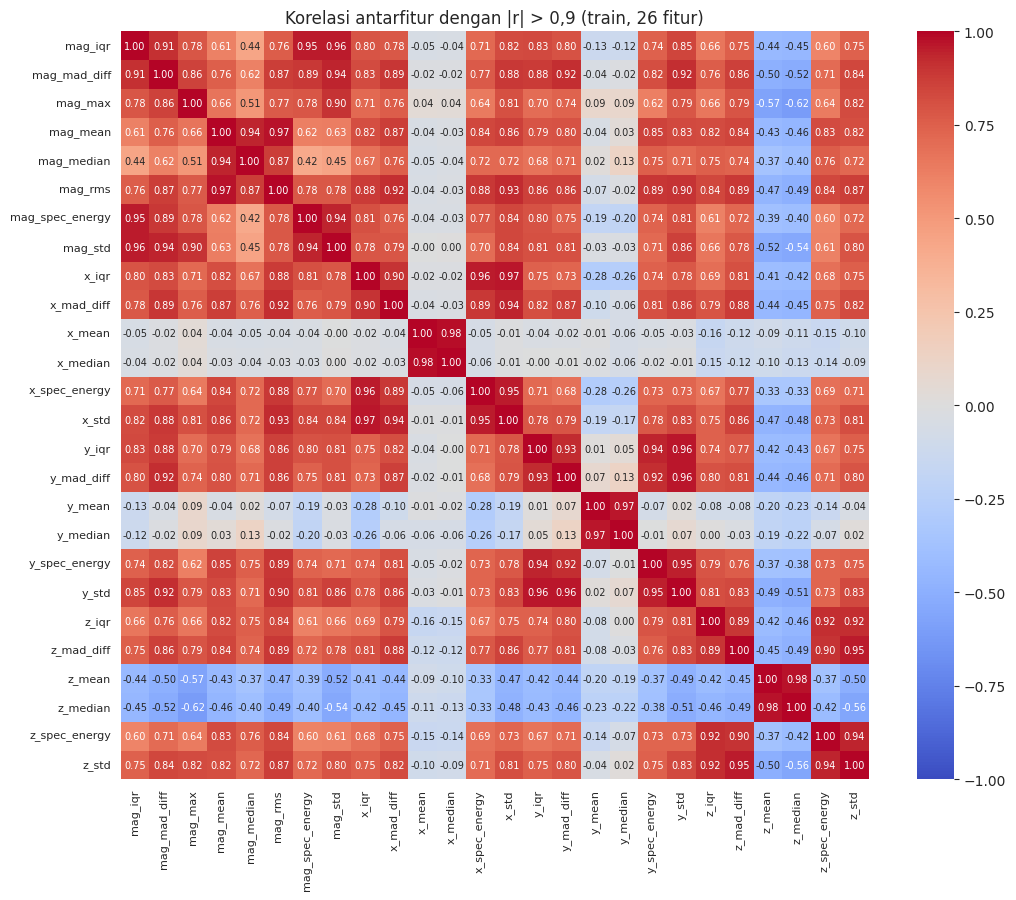

In [ ]:
fitur_tinggi = sorted(set([a for a, b in tinggi.index] + [b for a, b in tinggi.index]))

plt.figure(figsize=(11, 9))
sns.heatmap(kor.loc[fitur_tinggi, fitur_tinggi], annot=True, fmt=".2f", annot_kws={"size": 7},
            cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title(f"Korelasi antarfitur dengan |r| > 0,9 (train, {len(fitur_tinggi)} fitur)")
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.savefig(f"{HASIL}/korelasi_fitur_tinggi.png", dpi=150)
plt.show()

#### 11.3.3 Fitur yang paling sering terlibat

In [ ]:
terlibat = pd.Series([a for a, b in tinggi.index] + [b for a, b in tinggi.index]).value_counts()
print(terlibat.head(15))

# Heatmap 79 fitur disimpan untuk lampiran saja (tidak ditampilkan)
plt.figure(figsize=(16, 14))
sns.heatmap(kor, cmap="coolwarm", vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)
plt.tight_layout()
plt.savefig(f"{HASIL}/lampiran_korelasi_79_fitur.png", dpi=150)
plt.close()

y_std              5
x_std              4
mag_std            4
mag_mad_diff       4
mag_rms            4
y_mad_diff         4
x_mad_diff         3
z_std              3
mag_iqr            3
x_iqr              3
y_spec_energy      3
z_spec_energy      3
y_iqr              3
mag_mean           2
mag_spec_energy    2
Name: count, dtype: int64


#### 11.3.4 Hasil analisis korelasi antar fitur

Hanya 32 dari 3.081 pasangan fitur (1,0%) yang berkorelasi tinggi dengan |r| > 0,9. Redundansi ini terkumpul pada dua kelompok. Kelompok pertama adalah fitur posisi, yaitu mean dan median pada sumbu yang sama (r = 0,94 sampai 0,98). Kelompok kedua adalah fitur sebaran dan intensitas, yaitu simpangan baku, IQR, mad_diff, dan energi spektral pada sumbu yang sama (r = 0,90 sampai 0,97). Hubungan simpangan baku dengan energi spektral memang wajar, karena menurut teorema Parseval energi spektral sinyal tanpa komponen DC sebanding dengan variansnya. Fitur yang paling sering terlibat adalah y_std (5 pasangan), diikuti x_std, mag_std, mag_mad_diff, mag_rms, dan y_mad_diff (masing-masing 4 pasangan).

Heatmap juga memperlihatkan pola yang lebih luas. Fitur sebaran dari semua kanal saling berkorelasi sedang sampai tinggi (umumnya r = 0,6 sampai 0,9), karena saat ponsel bergerak kuat, semua sumbu ikut berfluktuasi. Sebaliknya, x_mean dan y_mean hampir tidak berkorelasi dengan fitur intensitas (|r| < 0,3), sehingga membawa informasi yang berbeda, yaitu arah gravitasi. Fitur z_mean dan z_median berkorelasi negatif dengan fitur intensitas (r sekitar −0,4 sampai −0,6), karena z_mean yang tinggi umumnya berasal dari Sitting, yang merupakan aktivitas statis dengan intensitas rendah.

Seluruh 79 fitur tetap dipertahankan. Proporsi pasangan yang redundan kecil, dan jumlah fitur jauh lebih sedikit daripada jumlah sampel train, sehingga risiko overfitting karena dimensi rendah. Random Forest relatif tahan terhadap fitur yang saling berkorelasi, dan SVM dengan kernel RBF tidak bergantung pada asumsi independensi fitur. Korelasi linear yang tinggi juga tidak berarti informasinya identik, misalnya energi spektral adalah fungsi kuadrat dari simpangan baku, bukan salinannya. Konsekuensinya, feature importance pada Random Forest akan terbagi di antara fitur yang berkorelasi, sehingga perlu ditafsirkan per kelompok fitur, bukan per fitur tunggal.

### 11.4 Kelompok Fitur

Fitur dikelompokkan menjadi domain waktu, domain frekuensi, dan antarsumbu. Pengelompokan ini dipakai untuk melihat pengaruh setiap kelompok fitur terhadap kinerja model di bagian 13.

In [ ]:
fitur_waktu = ["mean", "std", "min", "max", "median", "iqr", "rms", "skew", "kurt", "mad_diff", "zcr"]
kol_waktu = [c for c in F_train.columns if c.split("_", 1)[-1] in fitur_waktu]
kol_frek  = [c for c in F_train.columns if any(k in c for k in ["dom_freq", "spec_energy", "spec_entropy", "band_"])]
kol_antar = [c for c in F_train.columns if c.startswith("corr_")]

print(f"Fitur waktu = {len(kol_waktu)}, frekuensi = {len(kol_frek)}, antarsumbu = {len(kol_antar)}")
assert len(kol_waktu) + len(kol_frek) + len(kol_antar) == F_train.shape[1]

Fitur waktu = 44, frekuensi = 32, antarsumbu = 3


## 12. Pemilihan Hyperparameter untuk SVM dan Random Forest

Dua klasifikator digunakan. SVM dengan kernel RBF (Exp 1) dipilih karena efektif pada data berdimensi menengah dan mampu membentuk batas keputusan yang non-linear. SVM sensitif terhadap skala fitur, sehingga fitur dinormalisasi dengan StandardScaler yang di-fit hanya pada train, dibungkus dalam pipeline. Random Forest (Exp 2) dipilih karena tidak memerlukan normalisasi, tahan terhadap fitur yang saling berkorelasi, dan menyediakan feature importance.

Ketidakseimbangan kelas ditangani dengan `class_weight="balanced"`. Bobot dihitung dari distribusi kelas train, tanpa mengubah data dan tanpa oversampling.

Setiap kombinasi hyperparameter dilatih pada train dan dievaluasi pada validasi dengan macro-F1. Data test tidak digunakan sama sekali pada tahap ini. Macro-F1 train juga dicatat untuk melihat apakah ada kombinasi yang overfit.

### 12.1 SVM

In [ ]:
hasil_svm = []
for C, gamma in itertools.product([1, 10, 100], ["scale", 0.01, 0.1]):
    model = make_pipeline(StandardScaler(),
                          SVC(C=C, gamma=gamma, kernel="rbf", class_weight="balanced", random_state=SEED))
    t0 = time.perf_counter()
    model.fit(F_train, y_train)
    t_latih = time.perf_counter() - t0
    hasil_svm.append({
        "Model": "SVM", "C": C, "gamma": gamma,
        "Macro-F1 train": round(f1_score(y_train, model.predict(F_train), average="macro"), 4),
        "Macro-F1 val": round(f1_score(y_val, model.predict(F_val), average="macro"), 4),
        "Waktu latih (s)": round(t_latih, 2),
    })

tuning_svm = pd.DataFrame(hasil_svm).sort_values("Macro-F1 val", ascending=False)
display(tuning_svm)

,Model,C,gamma,Macro-F1 train,Macro-F1 val,Waktu latih (s)
4,SVM,10,0.01,0.9982,0.8856,0.87
3,SVM,10,scale,0.9992,0.8847,0.92
1,SVM,1,0.01,0.9858,0.8830,1.24
7,SVM,100,0.01,1.0000,0.8814,0.83
6,SVM,100,scale,1.0000,0.8804,0.93
0,SVM,1,scale,0.9891,0.8798,1.33
5,SVM,10,0.1,1.0000,0.6402,7.33
8,SVM,100,0.1,1.0000,0.6402,7.41
2,SVM,1,0.1,0.9990,0.6314,8.57


### 12.2 Random Forest

In [ ]:
hasil_rf = []
for n_est, depth, leaf in itertools.product([300], [None, 20], [1, 5]):
    model = RandomForestClassifier(n_estimators=n_est, max_depth=depth, min_samples_leaf=leaf,
                                   class_weight="balanced", n_jobs=-1, random_state=SEED)
    t0 = time.perf_counter()
    model.fit(F_train, y_train)
    t_latih = time.perf_counter() - t0
    hasil_rf.append({
        "Model": "RF", "n_estimators": n_est, "max_depth": depth, "min_samples_leaf": leaf,
        "Macro-F1 train": round(f1_score(y_train, model.predict(F_train), average="macro"), 4),
        "Macro-F1 val": round(f1_score(y_val, model.predict(F_val), average="macro"), 4),
        "Waktu latih (s)": round(t_latih, 2),
    })

tuning_rf = pd.DataFrame(hasil_rf).sort_values("Macro-F1 val", ascending=False)
display(tuning_rf)

,Model,n_estimators,max_depth,min_samples_leaf,Macro-F1 train,Macro-F1 val,Waktu latih (s)
0,RF,300,NaN,1,1.0000,0.9116,20.07
2,RF,300,20.0,1,1.0000,0.9104,19.79
1,RF,300,NaN,5,0.9948,0.9048,18.95
3,RF,300,20.0,5,0.9948,0.9032,18.84


### 12.3 Hasil pemilihan parameter SVM dan Random Forest

Pada SVM, kombinasi terbaik di validasi adalah C = 10 dan gamma = 0,01 dengan macro-F1 0,8856. Enam kombinasi teratas berada dalam rentang yang sangat sempit, yaitu 0,8798 sampai 0,8856, sehingga SVM cukup stabil terhadap pilihan C selama gamma tidak terlalu besar. Gamma = 0,1 menyebabkan overfitting berat. Macro-F1 train mencapai 0,999 sampai 1,000, tetapi validasi hanya 0,63 sampai 0,64. Kernel yang terlalu sempit membuat model menghafal titik-titik train. Kombinasi ini juga paling lambat dilatih (7,5 sampai 8,5 detik), karena hampir setiap sampel menjadi support vector.

Pada Random Forest, kombinasi terbaik adalah 300 pohon tanpa batas kedalaman dan min_samples_leaf = 1, dengan macro-F1 validasi 0,9116. Membatasi kedalaman menjadi 20 atau menaikkan min_samples_leaf menjadi 5 hanya menurunkan skor sedikit, menjadi 0,9032 sampai 0,9104.

Semua kombinasi yang wajar mencapai macro-F1 train sekitar 0,99 sampai 1,00, sementara macro-F1 validasi hanya 0,88 sampai 0,91. Selisih sekitar 0,09 sampai 0,12 ini menunjukkan bahwa tantangan utamanya adalah generalisasi ke subjek baru, bukan kapasitas model.

Hyperparameter final dipilih berdasarkan macro-F1 validasi tertinggi. Exp 1 menggunakan SVM kernel RBF dengan C = 10, gamma = 0,01, dan class_weight balanced. Exp 2 menggunakan Random Forest dengan 300 pohon, max_depth None, min_samples_leaf 1, dan class_weight balanced. Perlu dicatat bahwa selisih antarkombinasi teratas sangat kecil (di bawah 0,01), padahal validasi hanya berisi 5 subjek. Perbedaan sekecil ini kemungkinan masih dalam batas variasi acak, sehingga urutan peringkat kombinasi teratas tidak boleh ditafsirkan berlebihan.

## 13. Evaluasi SVM dan Random Forest pada Data Test

Hyperparameter sudah ditetapkan dari validasi, sehingga data test kini digunakan satu kali untuk evaluasi akhir dan tidak untuk memilih model. Setiap model dilatih ulang pada train dengan 5 seed (42, 7, 123, 2024, 99), dan hasilnya dilaporkan sebagai rata-rata ± simpangan baku.

Waktu pelatihan adalah waktu `fit` pada train dalam detik. Waktu inferensi per sampel adalah waktu `predict` pada seluruh data test dibagi jumlah jendela, dalam milidetik. Waktu ekstraksi fitur per sampel diukur terpisah dengan 5 kali pengulangan, lalu dijumlahkan dengan waktu inferensi model menjadi waktu inferensi total, karena ekstraksi fitur wajib dilakukan sebelum klasifikasi. Semua pengukuran dilakukan di CPU Google Colab.

SVM tidak memiliki komponen acak saat pelatihan (`random_state` hanya berpengaruh jika `probability=True`), sehingga hasilnya identik di semua seed dan simpangan bakunya 0. Random Forest bervariasi antarseed karena bootstrap sampling dan pemilihan fitur acak di setiap pohon.

### 13.1 Persiapan

#### 13.1.1 Hyperparameter final dan fungsi pembuat model

In [ ]:
PARAM_SVM = dict(C=10, gamma=0.01)
PARAM_RF  = dict(n_estimators=300, max_depth=None, min_samples_leaf=1)

def buat_model(nama, seed):
    if nama == "SVM":
        return make_pipeline(StandardScaler(),
                             SVC(kernel="rbf", class_weight="balanced", random_state=seed, **PARAM_SVM))
    return RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=seed, **PARAM_RF)

#### 13.1.2 Waktu ekstraksi fitur per sampel (data test, 5 kali)


In [ ]:
t_ekstraksi = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = ekstraksi_fitur(X_test)
    t_ekstraksi.append(time.perf_counter() - t0)

t_ekstraksi_ms = np.array(t_ekstraksi) / len(X_test) * 1000
print(f"Waktu ekstraksi fitur per sampel = {t_ekstraksi_ms.mean():.4f} ± {t_ekstraksi_ms.std():.4f} ms")

Waktu ekstraksi fitur per sampel = 0.0467 ± 0.0011 ms


#### 13.1.3 Fungsi bantu untuk evaluasi

In [ ]:
def tampilkan_cm(pred, judul, nama_file):
    """Classification report dan confusion matrix (jumlah dan ternormalisasi)."""
    print(classification_report(y_test, pred, target_names=kelas, digits=4))
    pd.DataFrame(classification_report(y_test, pred, target_names=kelas, output_dict=True)).T \
      .to_csv(f"{HASIL}/laporan_kelas_{nama_file}.csv")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=kelas, cmap="Blues",
                                            ax=axes[0], colorbar=False, xticks_rotation=45)
    axes[0].set_title(f"{judul}, jumlah")
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=kelas, cmap="Blues",
                                            normalize="true", values_format=".2f",
                                            ax=axes[1], colorbar=False, xticks_rotation=45)
    axes[1].set_title(f"{judul}, dinormalisasi per kelas asli (recall)")
    plt.tight_layout()
    plt.savefig(f"{HASIL}/confusion_matrix_{nama_file}.png", dpi=150)
    plt.show()

def prediksi_per_subjek(pred, kelas_asli):
    """Tabel prediksi untuk satu kelas asli, dirinci per subjek test."""
    m = y_test_txt == kelas_asli
    return pd.crosstab(g_test[m], le.inverse_transform(pred)[m], rownames=["Subjek"], colnames=["Prediksi"])

def mean_std(s, d=4):
    return f"{s.mean():.{d}f} ± {s.std():.{d}f}"

### 13.2 Pelatihan Ulang dengan 5 Seed

#### 13.2.1 Latih dan evaluasi SVM dan RF dengan 5 seed

In [ ]:
hasil_seed, prediksi = [], {}
for nama in ["SVM", "RF"]:
    for seed in SEEDS:
        set_seed(seed)
        model = buat_model(nama, seed)

        t0 = time.perf_counter()
        model.fit(F_train, y_train)
        t_latih = time.perf_counter() - t0

        t0 = time.perf_counter()
        pred = model.predict(F_test)
        t_inf = time.perf_counter() - t0

        hasil_seed.append({
            "Model": nama, "Seed": seed,
            "Macro-F1 val": f1_score(y_val, model.predict(F_val), average="macro"),
            "Accuracy test": accuracy_score(y_test, pred),
            "Macro-F1 test": f1_score(y_test, pred, average="macro"),
            "Waktu latih (s)": t_latih,
            "Inferensi model (ms/sampel)": t_inf / len(F_test) * 1000,
        })
        prediksi[(nama, seed)] = pred
        print(f"{nama} seed {seed}, macro-F1 test = {hasil_seed[-1]['Macro-F1 test']:.4f}, latih {t_latih:.2f} s")

per_seed = pd.DataFrame(hasil_seed)
per_seed["Inferensi total (ms/sampel)"] = per_seed["Inferensi model (ms/sampel)"] + t_ekstraksi_ms.mean()
per_seed.to_csv(f"{HASIL}/hasil_tradisional_per_seed.csv", index=False)

SVM seed 42, macro-F1 test = 0.8395, latih 0.89 s
SVM seed 7, macro-F1 test = 0.8395, latih 0.85 s
SVM seed 123, macro-F1 test = 0.8395, latih 0.85 s
SVM seed 2024, macro-F1 test = 0.8395, latih 0.88 s
SVM seed 99, macro-F1 test = 0.8395, latih 0.86 s
RF seed 42, macro-F1 test = 0.8299, latih 20.14 s
RF seed 7, macro-F1 test = 0.8490, latih 20.05 s
RF seed 123, macro-F1 test = 0.8373, latih 20.24 s
RF seed 2024, macro-F1 test = 0.8089, latih 25.65 s
RF seed 99, macro-F1 test = 0.8545, latih 19.86 s


#### 13.2.2 Ringkasan rata-rata ± simpangan baku


In [ ]:
kolom_ringkas = ["Accuracy test", "Macro-F1 test", "Macro-F1 val", "Waktu latih (s)",
                 "Inferensi model (ms/sampel)", "Inferensi total (ms/sampel)"]
tabel_tradisional = pd.DataFrame({
    m: {k: mean_std(per_seed.loc[per_seed.Model == m, k]) for k in kolom_ringkas}
    for m in ["SVM", "RF"]
}).T
display(tabel_tradisional)
tabel_tradisional.to_csv(f"{HASIL}/hasil_tradisional_ringkas.csv")

,Accuracy test,Macro-F1 test,Macro-F1 val,Waktu latih (s),Inferensi model (ms/sampel),Inferensi total (ms/sampel)
SVM,0.8745 ± 0.0000,0.8395 ± 0.0000,0.8856 ± 0.0000,0.8664 ± 0.0161,0.1800 ± 0.0089,0.2267 ± 0.0089
RF,0.9031 ± 0.0081,0.8359 ± 0.0179,0.9158 ± 0.0044,21.1871 ± 2.4983,0.0421 ± 0.0003,0.0888 ± 0.0003


### 13.3 Kinerja per Kelas

#### 13.3.1 F1 per kelas pada test (rata-rata ± simpangan baku, 5 seed)

In [ ]:
f1_kelas = pd.DataFrame(
    [f1_score(y_test, p, average=None) for p in prediksi.values()],
    index=pd.MultiIndex.from_tuples(prediksi.keys(), names=["Model", "Seed"]),
    columns=kelas,
)
tabel_kelas = pd.DataFrame({m: f1_kelas.loc[m].apply(mean_std) for m in ["SVM", "RF"]})
display(tabel_kelas)

,SVM,RF
Downstairs,0.7980 ± 0.0000,0.8190 ± 0.0065
Jogging,0.9174 ± 0.0000,0.9478 ± 0.0011
Sitting,0.8730 ± 0.0000,0.7709 ± 0.0567
Standing,0.8770 ± 0.0000,0.8061 ± 0.0315
Upstairs,0.6500 ± 0.0000,0.7169 ± 0.0230
Walking,0.9215 ± 0.0000,0.9547 ± 0.0055


#### 13.3.2 Classification report dan confusion matrix SVM (seed 42)

              precision    recall  f1-score   support

  Downstairs     0.7751    0.8223    0.7980       197
     Jogging     0.8739    0.9655    0.9174       696
     Sitting     0.9821    0.7857    0.8730       140
    Standing     0.7810    1.0000    0.8770       107
    Upstairs     0.6036    0.7042    0.6500       240
     Walking     0.9916    0.8607    0.9215       962

    accuracy                         0.8745      2342
   macro avg     0.8346    0.8564    0.8395      2342
weighted avg     0.8885    0.8745    0.8772      2342



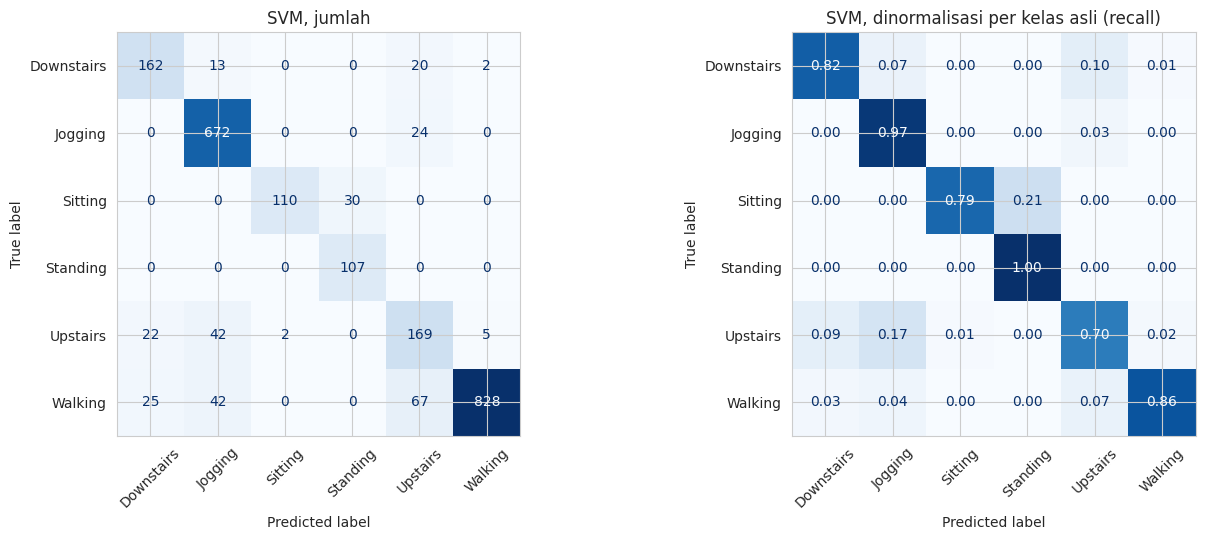

In [ ]:
tampilkan_cm(prediksi[("SVM", 42)], "SVM", "SVM")

#### 13.3.3 Classification report dan confusion matrix Random Forest (seed 42)

              precision    recall  f1-score   support

  Downstairs     0.9286    0.7259    0.8148       197
     Jogging     0.8992    1.0000    0.9469       696
     Sitting     1.0000    0.6071    0.7556       140
    Standing     0.6605    1.0000    0.7955       107
    Upstairs     0.8053    0.6375    0.7116       240
     Walking     0.9478    0.9626    0.9551       962

    accuracy                         0.9009      2342
   macro avg     0.8736    0.8222    0.8299      2342
weighted avg     0.9071    0.9009    0.8967      2342



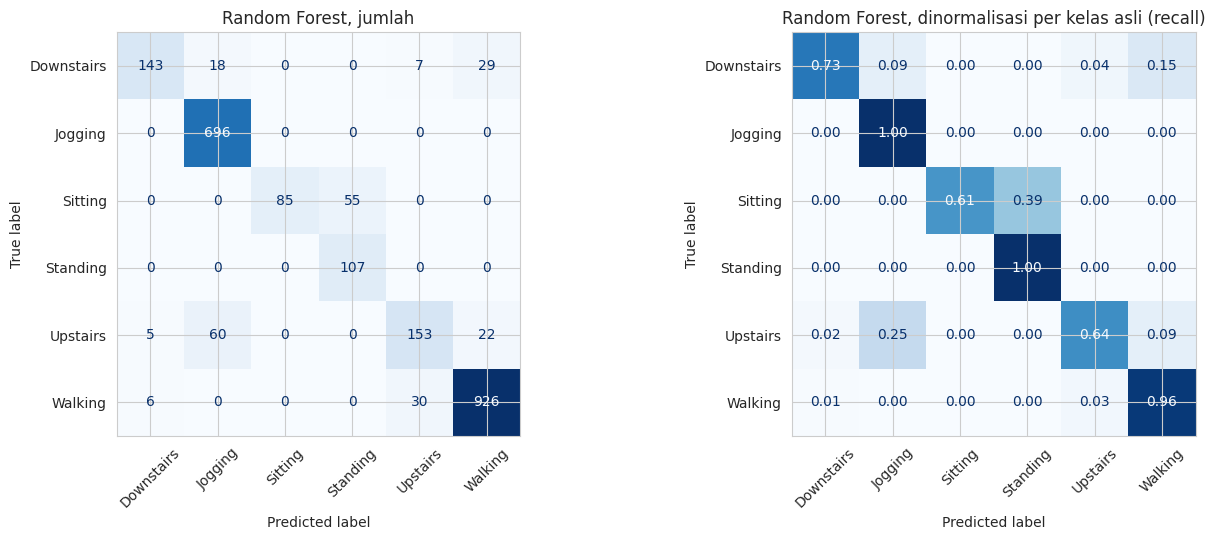

In [ ]:
tampilkan_cm(prediksi[("RF", 42)], "Random Forest", "RF")

### 13.4 Hasil evaluasi pelatihan ulang dengan 5 seed dan kinerja per kelas

| Model | Accuracy | Macro-F1 | Waktu latih (s) | Inferensi model (ms/sampel) | Inferensi total (ms/sampel) |
|---|---|---|---|---|---|
| SVM | 0,8745 ± 0,0000 | 0,8395 ± 0,0000 | 0,87 ± 0,02 | 0,180 ± 0,009 | 0,227 ± 0,009 |
| Random Forest | 0,9031 ± 0,0081 | 0,8359 ± 0,0179 | 21,19 ± 2,50 | 0,042 ± 0,000 | 0,089 ± 0,000 |

Inferensi total adalah waktu ekstraksi fitur (0,047 ± 0,001 ms per sampel) ditambah waktu prediksi model. Pengukuran dilakukan di CPU Google Colab dengan 2 core.

Macro-F1 kedua model praktis setara, yaitu 0,8395 untuk SVM dan 0,8359 ± 0,0179 untuk Random Forest. Rentang Random Forest antarseed (0,8089 sampai 0,8545) mencakup nilai SVM, sehingga tidak ada bukti bahwa salah satu model lebih unggul pada metrik utama. Accuracy Random Forest lebih tinggi (0,9031 dibanding 0,8745) karena lebih baik pada kelas mayoritas, yaitu Walking dan Jogging. Perbedaan ini hilang ketika setiap kelas diberi bobot yang sama dalam macro-F1, yang menunjukkan mengapa accuracy saja bisa menyesatkan pada data yang tidak seimbang.

Kinerja kedua model turun dari validasi ke test. SVM turun dari 0,8856 menjadi 0,8395 dan Random Forest dari 0,9158 menjadi 0,8359. Random Forest juga jauh lebih bervariasi di test (simpangan baku 0,018) dibanding di validasi (0,004). Ada tiga kemungkinan penyebab. Subjek test mungkin lebih sulit atau lebih berbeda dari subjek train, kualitas sampling di test lebih buruk (bagian 10.3), dan hyperparameter dipilih pada validasi yang hanya berisi 5 subjek sehingga sedikit menyesuaikan diri dengan subjek validasi. SVM menghasilkan nilai yang identik di kelima seed, sesuai sifatnya yang deterministik.

Upstairs adalah kelas tersulit pada kedua model, dengan F1 0,650 pada SVM dan 0,717 pada Random Forest. Pada Random Forest (seed 42), 25% jendela Upstairs diprediksi sebagai Jogging dan 9% sebagai Walking, sesuai dengan bagian 8.3 yang menunjukkan Upstairs mirip Walking dan Downstairs pada fitur domain waktu. Sitting juga sering diprediksi sebagai Standing. Recall Sitting hanya 0,61 pada Random Forest (55 dari 140 jendela salah ke Standing) dan 0,79 pada SVM, sehingga Standing memiliki recall 1,00 tetapi presisinya rendah (0,66 pada Random Forest dan 0,78 pada SVM). Hasil ini cukup mengejutkan, karena di train kedua kelas terpisah jelas oleh orientasi gravitasi, dan penyebabnya diperiksa di bagian 13.5. Downstairs memiliki recall 0,73 pada Random Forest, dengan 15% salah ke Walking dan 9% ke Jogging.

SVM sekitar 24 kali lebih cepat dilatih (0,87 dibanding 21,19 detik), tetapi Random Forest sekitar 4 kali lebih cepat saat inferensi model (0,042 dibanding 0,180 ms per sampel). Waktu inferensi SVM bergantung pada jumlah support vector, sedangkan Random Forest hanya menelusuri 300 pohon. Ekstraksi fitur sendiri (0,047 ms per sampel) memakan waktu sedikit lebih lama daripada inferensi model Random Forest. Pengukuran waktu di Colab dipengaruhi beban server bersama, sehingga perbandingan relatif antarmodel lebih bermakna daripada nilai absolutnya.

### 13.5 Analisis Kesalahan Sitting ke Standing

Bagian ini memeriksa apakah kesalahan Sitting ke Standing terkonsentrasi pada subjek tertentu, dan apakah orientasi ponsel subjek tersebut berbeda dari pola Sitting di train.

#### 13.5.1 Prediksi jendela Sitting per subjek test (seed 42)

In [ ]:
for nama in ["SVM", "RF"]:
    print(nama)
    display(prediksi_per_subjek(prediksi[(nama, 42)], "Sitting"))

SVM


Prediksi,Sitting,Standing
Subjek,,
12,32,0
16,42,0
19,36,0
27,0,30


RF


Prediksi,Sitting,Standing
Subjek,,
12,32,0
16,42,0
19,11,25
27,0,30


#### 13.5.2 Orientasi rata-rata jendela Sitting per subjek (train dan test)

In [ ]:
def orientasi(F, y_txt, g, kelas_nama):
    m = y_txt == kelas_nama
    return F.loc[m, ["x_mean", "y_mean", "z_mean"]].groupby(g[m]).mean().round(2)

print("Sitting per subjek train")
display(orientasi(F_train, y_train_txt, g_train, "Sitting"))
print("Sitting per subjek test")
display(orientasi(F_test, y_test_txt, g_test, "Sitting"))
print("Standing rata-rata train")
display(F_train.loc[y_train_txt == "Standing", ["x_mean", "y_mean", "z_mean"]].mean().round(2).to_frame("mean").T)

Sitting per subjek train


,x_mean,y_mean,z_mean
3,1.39,0.06,9.67
4,-6.97,-0.75,-6.94
5,4.26,3.04,8.04
6,6.42,2.47,6.51
7,-6.48,-3.37,6.79
8,-0.87,-1.56,9.50
18,5.56,1.77,8.40
20,-1.91,4.06,8.62
30,4.34,7.11,-6.02
31,0.94,-0.14,9.68


Sitting per subjek test


,x_mean,y_mean,z_mean
12,8.14,-2.11,4.00
16,5.46,2.55,8.25
19,8.96,-0.80,2.26
27,3.21,9.30,1.14


Standing rata-rata train


,x_mean,y_mean,z_mean
mean,-0.91,8.93,0.93


#### 13.5.3 Hasil analisis kesalahan sitting ke standing

Kesalahan Sitting ke Standing tidak tersebar merata, tetapi terkonsentrasi pada subjek tertentu. Seluruh 30 jendela Sitting milik subjek 27 diprediksi sebagai Standing oleh kedua model. Pada subjek 19, SVM benar semua (36 dari 36), tetapi Random Forest salah pada 25 dari 36 jendela. Subjek 12 dan 16 dikenali dengan benar seluruhnya oleh kedua model.

Penyebab kesalahan pada subjek 27 adalah orientasi ponsel. Orientasi Sitting subjek ini (x = 3,21, y = 9,30, z = 1,14) hampir sama dengan orientasi rata-rata Standing di train (x = −0,91, y = 8,93, z = 0,93), yaitu gravitasi dominan di sumbu y. Sebaliknya, sebagian besar subjek train merekam Sitting dengan gravitasi dominan di sumbu z (z_mean 6,5 sampai 9,7). Orientasi Sitting di train memang beragam, ada yang dominan di +z, di −z (subjek 4 dan 30), dan di x (subjek 32 dengan x = 8,12). Namun tidak ada satu pun subjek train yang merekam Sitting dengan gravitasi dominan di sumbu y seperti subjek 27. Subjek 19 (x = 8,96, z = 2,26) mirip dengan subjek 32 di train. SVM berhasil mengenalinya, sedangkan Random Forest sebagian besar gagal. Batas keputusan SVM yang lebih halus tampaknya lebih mampu menjangkau orientasi yang jarang muncul di train.

Sitting dan Standing adalah postur statis yang hampir tanpa gerakan, sehingga satu-satunya pembeda adalah arah gravitasi relatif terhadap ponsel. Jika seorang subjek meletakkan ponsel sehingga orientasinya saat duduk sama dengan orientasi umum saat berdiri, informasi pembedanya memang tidak ada di dalam sinyal. Ini merupakan keterbatasan data, yaitu satu akselerometer di saku dengan posisi ponsel yang tidak dikontrol, bukan semata kelemahan model. Karena subjek 27 menyumbang 30 dari 140 jendela Sitting di test (21%), skor Sitting di test sangat dipengaruhi oleh satu orang ini.

Keterbatasan ini dibahas di bagian Pembahasan dan Keterbatasan. Untuk penelitian lanjutan, beberapa hal yang bisa dicoba adalah data train dengan posisi ponsel yang lebih beragam, sensor tambahan seperti giroskop atau sensor di pergelangan tangan, atau fitur yang tidak bergantung pada orientasi.

### 13.6 Pengaruh Kelompok Fitur

Model dilatih dengan beberapa kombinasi kelompok fitur menggunakan hyperparameter yang sama dengan bagian 13.1, yaitu domain waktu saja (44 fitur), domain frekuensi saja (32 fitur), waktu dan frekuensi (76 fitur), serta semua fitur (79 fitur) sebagai konfigurasi utama. Hasil ini tidak digunakan untuk memilih model, melainkan untuk analisis. Keterbatasannya, hyperparameter dipilih menggunakan seluruh 79 fitur, sehingga kombinasi lain mungkin tidak berada pada hyperparameter terbaiknya.

#### 13.6.1 Latih model dengan tiap kombinasi kelompok fitur

In [ ]:
def urut_asli(kolom):
    kolom = set(kolom)
    return [c for c in F_train.columns if c in kolom]

set_fitur = {
    "Waktu (44)": urut_asli(kol_waktu),
    "Frekuensi (32)": urut_asli(kol_frek),
    "Waktu + Frekuensi (76)": urut_asli(kol_waktu + kol_frek),
    "Semua (79)": list(F_train.columns),
}

hasil_abl = []
for nama_set, kol in set_fitur.items():
    for nama in ["SVM", "RF"]:
        for seed in ([SEED] if nama == "SVM" else SEEDS):     # SVM deterministik, cukup 1 kali
            set_seed(seed)
            model = buat_model(nama, seed)
            model.fit(F_train[kol], y_train)
            hasil_abl.append({
                "Fitur": nama_set, "Model": nama, "Seed": seed,
                "Macro-F1 val": f1_score(y_val, model.predict(F_val[kol]), average="macro"),
                "Macro-F1 test": f1_score(y_test, model.predict(F_test[kol]), average="macro"),
            })
    print("Selesai", nama_set)

abl = pd.DataFrame(hasil_abl)
abl.to_csv(f"{HASIL}/ablasi_kelompok_fitur.csv", index=False)

Selesai Waktu (44)
Selesai Frekuensi (32)
Selesai Waktu + Frekuensi (76)
Selesai Semua (79)


#### 13.6.2 Ringkasan pengaruh kelompok fitur


In [ ]:
tabel_abl = abl.groupby(["Model", "Fitur"], sort=False)[["Macro-F1 val", "Macro-F1 test"]] \
               .agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1) if len(s) > 1 else 0:.4f}")
display(tabel_abl)

,,Macro-F1 val,Macro-F1 test
Model,Fitur,,
SVM,Waktu (44),0.8433 ± 0.0000,0.7417 ± 0.0000
RF,Waktu (44),0.8379 ± 0.0041,0.7242 ± 0.0111
SVM,Frekuensi (32),0.7976 ± 0.0000,0.7747 ± 0.0000
RF,Frekuensi (32),0.8572 ± 0.0033,0.8052 ± 0.0039
SVM,Waktu + Frekuensi (76),0.8921 ± 0.0000,0.8137 ± 0.0000
RF,Waktu + Frekuensi (76),0.9142 ± 0.0069,0.8221 ± 0.0087
SVM,Semua (79),0.8856 ± 0.0000,0.8395 ± 0.0000
RF,Semua (79),0.9158 ± 0.0044,0.8359 ± 0.0179


#### 13.6.3 Hasil pengaruh kelompok fitur

| Fitur | SVM val | SVM test | RF val | RF test |
|---|---|---|---|---|
| Waktu (44) | 0,8433 | 0,7417 | 0,8379 ± 0,0041 | 0,7242 ± 0,0111 |
| Frekuensi (32) | 0,7976 | 0,7747 | 0,8572 ± 0,0033 | 0,8052 ± 0,0039 |
| Waktu + Frekuensi (76) | 0,8921 | 0,8137 | 0,9142 ± 0,0069 | 0,8221 ± 0,0087 |
| Semua (79) | 0,8856 | 0,8395 | 0,9158 ± 0,0044 | 0,8359 ± 0,0179 |

Menggabungkan fitur domain waktu dan frekuensi memberi peningkatan terbesar. Dibanding fitur waktu saja, macro-F1 test naik 0,072 pada SVM dan 0,098 pada Random Forest. Kedua kelompok saling melengkapi, karena fitur waktu menangkap orientasi dan intensitas, sedangkan fitur frekuensi menangkap ritme gerakan.

Di test, fitur frekuensi saja justru lebih baik daripada fitur waktu saja, yaitu 0,7747 dibanding 0,7417 pada SVM dan 0,8052 dibanding 0,7242 pada Random Forest. Penurunan dari validasi ke test juga paling kecil pada fitur frekuensi (0,052 pada Random Forest, dibanding 0,114 pada fitur waktu). Dugaannya, sebagian besar fitur frekuensi seperti proporsi energi per pita, entropi, dan frekuensi dominan tidak bergantung pada orientasi ponsel, sehingga lebih tahan terhadap variasi antarsubjek. Fitur waktu memuat mean per sumbu yang sangat bergantung pada orientasi, seperti terlihat di bagian 13.5.

Urutan peringkat di validasi tidak selalu sama dengan di test. Pada SVM, fitur waktu lebih baik di validasi (0,8433 dibanding 0,7976) tetapi lebih buruk di test. Hal ini menunjukkan bahwa validasi dengan 5 subjek merupakan perkiraan yang cukup bising.

Penambahan 3 fitur korelasi antarsumbu memberi dampak kecil, yaitu naik 0,026 pada SVM dan 0,014 pada Random Forest. Kenaikan pada Random Forest masih lebih kecil daripada simpangan baku antarseed (0,018), sehingga tidak bisa disimpulkan bermakna.

## 14. Pendekatan Deep Learning, 1D-CNN

Masukan model adalah segmen sinyal mentah berukuran 128 sampel × 3 kanal, yaitu jendela yang sama persis dengan yang dipakai pendekatan tradisional, sehingga data train, validasi, dan test identik untuk semua model. Satuan masukan adalah percepatan dalam skala WISDM (10 = 1g) yang kemudian dinormalisasi.

Normalisasi dilakukan per kanal (x, y, z) dengan mean dan simpangan baku yang dihitung hanya dari data train, lalu diterapkan ke validasi dan test. Normalisasi dilakukan secara global per kanal, bukan per jendela, agar informasi orientasi gravitasi tetap terjaga karena informasi ini penting untuk membedakan Sitting dan Standing. Ketidakseimbangan kelas ditangani dengan class weight dari train, yang diterapkan pada fungsi loss.

### 14.1 Persiapan Data

#### 14.1.1 Normalisasi per kanal (mean dan std dari train)


In [ ]:
mu_kanal  = X_train.mean(axis=(0, 1), keepdims=True)
std_kanal = X_train.std(axis=(0, 1), keepdims=True)
print("Mean per kanal (train) =", mu_kanal.ravel().round(3))
print("Std per kanal (train)  =", std_kanal.ravel().round(3))

Xn_train = ((X_train - mu_kanal) / std_kanal).astype(np.float32)
Xn_val   = ((X_val   - mu_kanal) / std_kanal).astype(np.float32)
Xn_test  = ((X_test  - mu_kanal) / std_kanal).astype(np.float32)

for nama, Xn in [("Train", Xn_train), ("Val", Xn_val), ("Test", Xn_test)]:
    print(f"{nama}, mean = {Xn.mean(axis=(0, 1)).round(3)}, std = {Xn.std(axis=(0, 1)).round(3)}")

Mean per kanal (train) = [0.481 7.687 0.335]
Std per kanal (train)  = [6.791 6.434 4.921]
Train, mean = [0. 0. 0.], std = [1. 1. 1.]
Val, mean = [ 0.104 -0.106  0.11 ], std = [0.88  1.19  0.927]
Test, mean = [ 0.117 -0.206 -0.008], std = [1.114 1.081 0.882]


#### 14.1.2 Class weight dari train

In [ ]:
kelas_unik = np.unique(y_train)
bobot = len(y_train) / (len(kelas_unik) * np.bincount(y_train))
class_weight = {int(k): float(w) for k, w in zip(kelas_unik, bobot)}
print({kelas[k]: round(w, 3) for k, w in class_weight.items()})

{np.str_('Downstairs'): 1.966, np.str_('Jogging'): 0.554, np.str_('Sitting'): 2.875, np.str_('Standing'): 3.661, np.str_('Upstairs'): 1.543, np.str_('Walking'): 0.414}


#### 14.1.3 Hasil persiapan data

Mean per kanal di train adalah 0,481 untuk x, 7,687 untuk y, dan 0,335 untuk z. Nilai y yang besar menunjukkan bahwa gravitasi umumnya dominan di sumbu y, karena ponsel cenderung tegak di dalam saku. Simpangan baku per kanal adalah 6,791, 6,434, dan 4,921. Setelah normalisasi, train memiliki mean 0 dan simpangan baku 1. Validasi dan test sedikit bergeser, dengan mean antara −0,21 dan 0,12 serta simpangan baku antara 0,88 dan 1,19. Pergeseran ini wajar karena parameter normalisasi hanya diambil dari train, dan sekaligus menunjukkan adanya perbedaan distribusi antara subjek train dan subjek baru.

Class weight dari train adalah 3,661 untuk Standing, 2,875 untuk Sitting, 1,966 untuk Downstairs, 1,543 untuk Upstairs, 0,554 untuk Jogging, dan 0,414 untuk Walking. Dengan bobot ini, kesalahan pada kelas kecil diberi pengaruh lebih besar dalam loss.

### 14.2 Arsitektur dan Fungsi Pelatihan

Model terdiri atas 4 lapisan Conv1D dengan 64, 64, 128, dan 128 filter, ukuran kernel 5, 5, 3, dan 3, aktivasi ReLU, dan padding same. Setiap lapisan konvolusi diikuti Batch Normalization. Setelah blok pertama terdapat MaxPooling1D (ukuran 2) dan Dropout 0,3. Bagian akhir model terdiri atas Global Average Pooling, Dropout 0,5, dan lapisan Dense 6 kelas dengan aktivasi softmax.

Konvolusi 1D mempelajari pola lokal pada sinyal secara otomatis, misalnya bentuk satu langkah kaki. Kernel berukuran 5 pada 20 Hz mencakup 0,25 detik. Global Average Pooling membuat model tidak bergantung pada posisi pola di dalam jendela dan menekan jumlah parameter, sedangkan Dropout dan Batch Normalization membantu mengendalikan overfitting.

Model dilatih dengan optimizer Adam (learning rate 0,001), loss sparse categorical cross-entropy dengan class weight, batch size 64, dan maksimum 100 epoch. Early stopping memantau val_loss dengan patience 10 dan mengembalikan bobot terbaik.

#### 14.2.1 Konstanta pelatihan dan lapisan augmentasi

In [ ]:
N_KELAS = len(kelas)
LR = 1e-3
BATCH = 64
MAX_EPOCH = 100

class SkalaAcak(layers.Layer):
    """Augmentasi, kalikan tiap jendela dengan faktor acak per kanal (hanya aktif saat training)."""
    def __init__(self, rentang=0.1, **kwargs):
        super().__init__(**kwargs)
        self.rentang = rentang

    def call(self, x, training=None):
        if not training:
            return x
        faktor = tf.random.uniform((tf.shape(x)[0], 1, tf.shape(x)[2]), 1 - self.rentang, 1 + self.rentang)
        return x * faktor

#### 14.2.2 Fungsi pembangun model (baseline dan varian)


In [ ]:
def bangun_cnn(l2=0.0, drop1=0.3, drop2=0.5, augmentasi=False):
    reg = regularizers.l2(l2) if l2 > 0 else None
    blok = [layers.Input(shape=(WIN, 3))]
    if augmentasi:
        blok += [SkalaAcak(0.1), layers.GaussianNoise(0.05)]
    blok += [
        layers.Conv1D(64, 5, padding="same", activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Conv1D(64, 5, padding="same", activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Dropout(drop1),
        layers.Conv1D(128, 3, padding="same", activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.Conv1D(128, 3, padding="same", activation="relu", kernel_regularizer=reg),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(drop2),
        layers.Dense(N_KELAS, activation="softmax", kernel_regularizer=reg),
    ]
    model = keras.Sequential(blok)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

#### 14.2.3 Fungsi pelatihan dan konfigurasi baseline

In [ ]:
CFG_BASELINE = dict(arsitektur=dict(), reduce_lr=False, patience=10)

def latih_cnn(cfg, seed, verbose=0):
    set_seed(seed)
    model = bangun_cnn(**cfg["arsitektur"])
    cb = [EarlyStopping(monitor="val_loss", patience=cfg["patience"], restore_best_weights=True)]
    if cfg["reduce_lr"]:
        cb.append(ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5))
    t0 = time.perf_counter()
    riw = model.fit(Xn_train, y_train, validation_data=(Xn_val, y_val), epochs=MAX_EPOCH,
                    batch_size=BATCH, class_weight=class_weight, callbacks=cb, verbose=verbose)
    return model, riw.history, time.perf_counter() - t0

def macro_f1(model, X, y):
    return f1_score(y, model.predict(X, verbose=0).argmax(1), average="macro")

### 14.3 Pelatihan Awal (Seed 42)

#### 14.3.1 Ringkasan arsitektur

In [ ]:
bangun_cnn().summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 128, 64)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 64)        │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 64, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 64, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,862 (382.27 KB)

 Trainable params: 97,094 (379.27 KB)

 Non-trainable params: 768 (3.00 KB)

#### 14.3.2 Latih baseline dengan seed 42

In [ ]:
cnn, h, t_latih = latih_cnn(CFG_BASELINE, SEED, verbose=2)
epoch_terbaik = int(np.argmin(h["val_loss"])) + 1

print(f"\nWaktu latih = {t_latih:.1f} s, epoch dijalankan = {len(h['loss'])}, epoch terbaik = {epoch_terbaik}")
print(f"Macro-F1 train = {macro_f1(cnn, Xn_train, y_train):.4f}")
print(f"Macro-F1 val   = {macro_f1(cnn, Xn_val, y_val):.4f}")

Epoch 1/100
172/172 - 10s - 58ms/step - accuracy: 0.8418 - loss: 0.4664 - val_accuracy: 0.1854 - val_loss: 3.4618
Epoch 2/100
172/172 - 2s - 12ms/step - accuracy: 0.9599 - loss: 0.1542 - val_accuracy: 0.6660 - val_loss: 1.2207
Epoch 3/100
172/172 - 2s - 12ms/step - accuracy: 0.9746 - loss: 0.0982 - val_accuracy: 0.8184 - val_loss: 0.8194
Epoch 4/100
172/172 - 2s - 11ms/step - accuracy: 0.9827 - loss: 0.0660 - val_accuracy: 0.7980 - val_loss: 1.2093
Epoch 5/100
172/172 - 2s - 12ms/step - accuracy: 0.9784 - loss: 0.0839 - val_accuracy: 0.8023 - val_loss: 1.0918
Epoch 6/100
172/172 - 2s - 12ms/step - accuracy: 0.9858 - loss: 0.0566 - val_accuracy: 0.8340 - val_loss: 0.8913
Epoch 7/100
172/172 - 2s - 12ms/step - accuracy: 0.9867 - loss: 0.0555 - val_accuracy: 0.8179 - val_loss: 1.1500
Epoch 8/100
172/172 - 2s - 12ms/step - accuracy: 0.9903 - loss: 0.0410 - val_accuracy: 0.8321 - val_loss: 0.8999
Epoch 9/100
172/172 - 2s - 12ms/step - accuracy: 0.9952 - loss: 0.0232 - val_accuracy: 0.8169 -

#### 14.3.3 Kurva loss dan accuracy


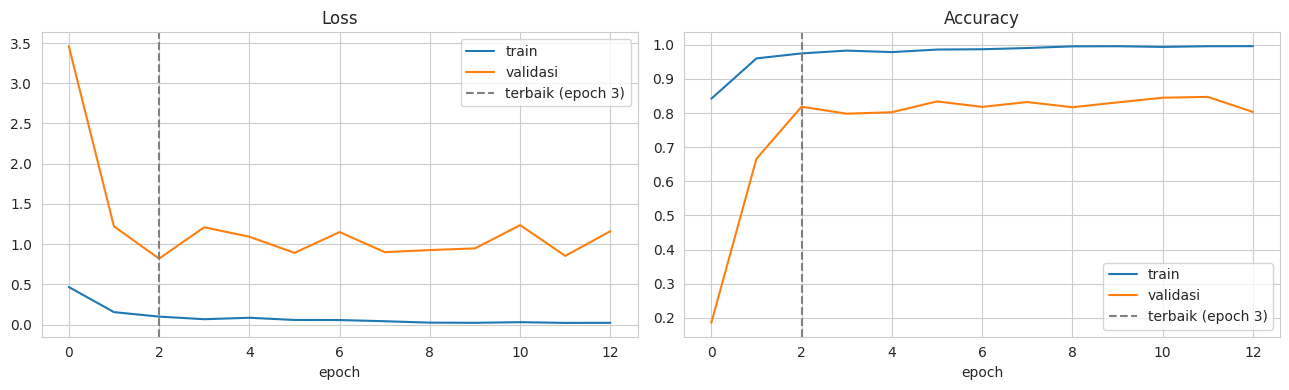

val_loss per epoch = [3.462, 1.221, 0.819, 1.209, 1.092, 0.891, 1.15, 0.9, 0.926, 0.947, 1.236, 0.854, 1.161]


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrik, judul in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
    ax.plot(h[metrik], label="train")
    ax.plot(h[f"val_{metrik}"], label="validasi")
    ax.axvline(epoch_terbaik - 1, ls="--", c="gray", label=f"terbaik (epoch {epoch_terbaik})")
    ax.set_title(judul)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{HASIL}/kurva_loss_cnn_seed42.png", dpi=150)
plt.show()

print("val_loss per epoch =", [round(v, 3) for v in h["val_loss"]])

#### 14.3.4 Hasil pelatihan awal

Model memiliki 97.862 parameter, terdiri atas 97.094 parameter yang dilatih dan 768 parameter non-trainable dari Batch Normalization. Early stopping menghentikan pelatihan pada epoch 13, dan bobot terbaik diambil dari epoch 3 dengan val_loss 0,819.

Kurva menunjukkan indikasi overfitting yang jelas. Loss train terus turun hingga sekitar 0,02 dengan akurasi train sekitar 0,996, sedangkan loss validasi tidak pernah turun di bawah 0,82 dan akurasi validasi tertahan di 0,80 sampai 0,85. Macro-F1 train dari bobot terbaik adalah 0,9594, sedangkan macro-F1 validasi 0,8316, sehingga selisihnya sekitar 0,13. Pola ini sama dengan pendekatan tradisional, yaitu model mudah menghafal subjek train tetapi kesulitan menggeneralisasi ke subjek baru.

Loss validasi juga fluktuatif, naik turun antara 0,82 dan 1,24 dari satu epoch ke epoch berikutnya tanpa tren menurun setelah epoch 3. Kemungkinan penyebabnya adalah validasi yang hanya berisi 5 subjek dengan jendela yang saling berkorelasi, efek Batch Normalization, dan class weight yang memperbesar kesalahan pada kelas kecil. Akibatnya, epoch terbaik sebagian dipengaruhi kebetulan, karena epoch-epoch berikutnya memiliki val_loss yang tidak jauh berbeda, misalnya 0,85 pada epoch 12. Macro-F1 validasi CNN (0,8316) juga masih di bawah SVM (0,8856) dan Random Forest (0,9158).

Epoch pertama membutuhkan 10 detik untuk inisialisasi GPU, sedangkan epoch berikutnya sekitar 2 detik, dengan total waktu latih 34 detik. Karena val_loss fluktuatif dan terjadi overfitting, beberapa varian pengaturan dibandingkan pada validasi di bagian 14.4 sebelum konfigurasi final ditetapkan. Langkah ini juga membuat perbandingan lebih adil, karena pendekatan tradisional sudah melalui pemilihan 13 kombinasi hyperparameter.

### 14.4 Pemilihan Varian (Validasi)

| Varian | Perubahan dari baseline | Tujuan |
|---|---|---|
| A, baseline | konfigurasi 14.3 | pembanding |
| B, ReduceLR | learning rate dikali 0,5 jika val_loss tidak membaik selama 4 epoch (minimum 1e-5), early stopping patience 15 | menstabilkan pelatihan |
| C, B + L2 dan dropout | B ditambah regularisasi L2 1e-4 dan dropout blok pertama 0,5 | menekan overfitting |
| D, B + augmentasi | B ditambah skala acak per kanal ±10% dan derau Gaussian σ = 0,05, hanya saat training | meniru variasi antarsubjek |

Setiap varian dilatih dengan 3 seed (42, 7, 123) dan dievaluasi pada validasi. Varian dengan rata-rata macro-F1 validasi tertinggi dipilih sebagai konfigurasi final, dan data test tidak digunakan. Augmentasi rotasi sengaja tidak dipakai, karena orientasi gravitasi adalah pembeda utama Sitting dan Standing (bagian 8.3 dan 13.4), sehingga memutar sinyal secara acak berisiko menghapus informasi tersebut. Augmentasi dipasang sebagai lapisan di dalam model yang hanya aktif saat training, sehingga data validasi dan test tidak pernah diaugmentasi.

#### 14.4.1 Latih setiap varian dengan 3 seed


In [ ]:
VARIAN = {
    "A, baseline":         CFG_BASELINE,
    "B, ReduceLR":         dict(arsitektur=dict(), reduce_lr=True, patience=15),
    "C, B + L2 & dropout": dict(arsitektur=dict(l2=1e-4, drop1=0.5), reduce_lr=True, patience=15),
    "D, B + augmentasi":   dict(arsitektur=dict(augmentasi=True), reduce_lr=True, patience=15),
}
SEED_SELEKSI = [42, 7, 123]

hasil_var, riwayat_var = [], {}
for nama_var, cfg in VARIAN.items():
    for seed in SEED_SELEKSI:
        model, hh, t = latih_cnn(cfg, seed)
        hasil_var.append({
            "Varian": nama_var, "Seed": seed,
            "Macro-F1 train": macro_f1(model, Xn_train, y_train),
            "Macro-F1 val": macro_f1(model, Xn_val, y_val),
            "Epoch terbaik": int(np.argmin(hh["val_loss"])) + 1,
            "Epoch dijalankan": len(hh["loss"]),
            "Waktu latih (s)": t,
        })
        riwayat_var[(nama_var, seed)] = hh
        b = hasil_var[-1]
        print(f"{nama_var}, seed {seed}, F1 val = {b['Macro-F1 val']:.4f}, "
              f"epoch terbaik {b['Epoch terbaik']}/{b['Epoch dijalankan']}, {t:.1f} s")

var_df = pd.DataFrame(hasil_var)
var_df.to_csv(f"{HASIL}/seleksi_varian_cnn.csv", index=False)

A, baseline, seed 42, F1 val = 0.8316, epoch terbaik 3/13, 31.8 s
A, baseline, seed 7, F1 val = 0.8758, epoch terbaik 3/13, 29.9 s
A, baseline, seed 123, F1 val = 0.7863, epoch terbaik 3/13, 31.2 s
B, ReduceLR, seed 42, F1 val = 0.8316, epoch terbaik 3/18, 40.9 s
B, ReduceLR, seed 7, F1 val = 0.8758, epoch terbaik 3/18, 41.2 s
B, ReduceLR, seed 123, F1 val = 0.7863, epoch terbaik 3/18, 40.4 s
C, B + L2 & dropout, seed 42, F1 val = 0.8277, epoch terbaik 6/21, 48.2 s
C, B + L2 & dropout, seed 7, F1 val = 0.8796, epoch terbaik 6/21, 47.3 s
C, B + L2 & dropout, seed 123, F1 val = 0.7749, epoch terbaik 3/18, 41.4 s
D, B + augmentasi, seed 42, F1 val = 0.8767, epoch terbaik 12/27, 71.4 s
D, B + augmentasi, seed 7, F1 val = 0.8102, epoch terbaik 3/18, 43.3 s
D, B + augmentasi, seed 123, F1 val = 0.8324, epoch terbaik 3/18, 41.2 s


#### 14.4.2 Ringkasan dan pemilihan varian


In [ ]:
kol_var = ["Macro-F1 train", "Macro-F1 val", "Epoch terbaik", "Waktu latih (s)"]
ring_var = var_df.groupby("Varian", sort=False)[kol_var].agg(["mean", "std"])
display(ring_var.round(4))

VARIAN_TERPILIH = ring_var[("Macro-F1 val", "mean")].idxmax()
CFG_FINAL = VARIAN[VARIAN_TERPILIH]
print("Varian terpilih (rata-rata macro-F1 val tertinggi) =", VARIAN_TERPILIH)

Macro-F1 train         Macro-F1 val         Epoch terbaik  \
                              mean     std         mean     std          mean   
Varian                                                                          
A, baseline                 0.9709  0.0126       0.8312  0.0448           3.0   
B, ReduceLR                 0.9709  0.0126       0.8312  0.0448           3.0   
C, B + L2 & dropout         0.9616  0.0219       0.8274  0.0523           5.0   
D, B + augmentasi           0.9643  0.0279       0.8397  0.0339           6.0   

                            Waktu latih (s)           
                        std            mean      std  
Varian                                                
A, baseline          0.0000         30.9725   1.0010  
B, ReduceLR          0.0000         40.8179   0.4258  
C, B + L2 & dropout  1.7321         45.6135   3.7111  
D, B + augmentasi    5.1962         51.9516  16.8545

Varian terpilih (rata-rata macro-F1 val tertinggi) = D, B + augmentasi


#### 14.4.3 Kurva loss seed 42 untuk setiap varian


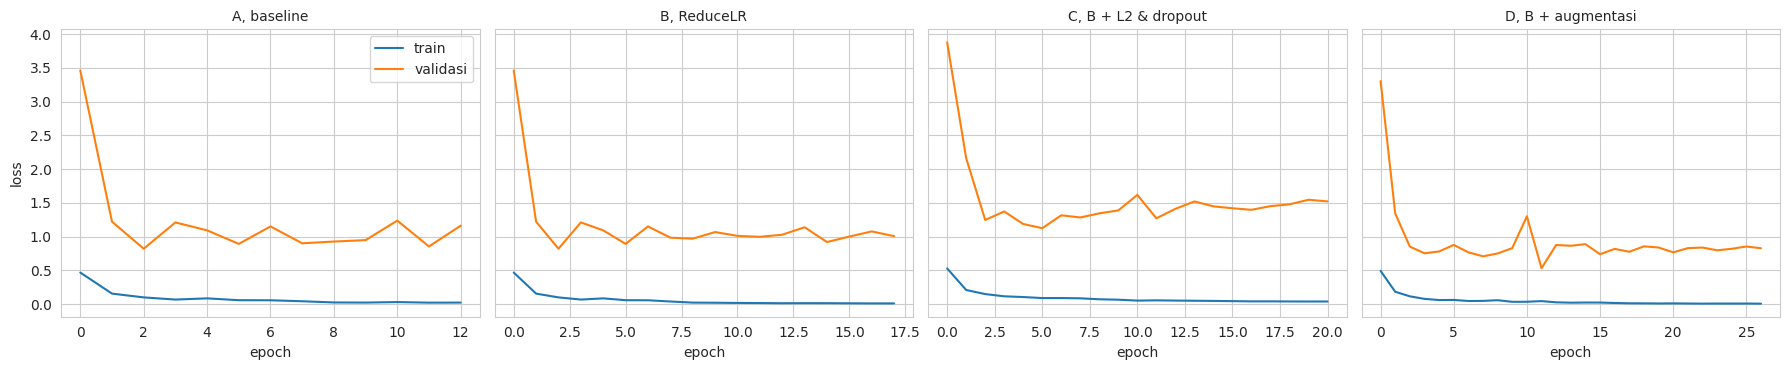

In [ ]:
fig, axes = plt.subplots(1, len(VARIAN), figsize=(18, 3.8), sharey=True)
for ax, nama_var in zip(axes, VARIAN):
    hh = riwayat_var[(nama_var, 42)]
    ax.plot(hh["loss"], label="train")
    ax.plot(hh["val_loss"], label="validasi")
    ax.set_title(nama_var, fontsize=10)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{HASIL}/kurva_loss_varian_cnn.png", dpi=150)
plt.show()

#### 14.4.4 Hasil pemilihan varian

| Varian | Macro-F1 train | Macro-F1 val | Epoch terbaik | Waktu latih (s) |
|---|---|---|---|---|
| A, baseline | 0,9709 ± 0,0126 | 0,8312 ± 0,0448 | 3,0 ± 0,0 | 31,0 ± 1,0 |
| B, ReduceLR | 0,9709 ± 0,0126 | 0,8312 ± 0,0448 | 3,0 ± 0,0 | 40,8 ± 0,4 |
| C, B + L2 dan dropout | 0,9616 ± 0,0219 | 0,8274 ± 0,0523 | 5,0 ± 1,7 | 45,6 ± 3,7 |
| D, B + augmentasi | 0,9643 ± 0,0279 | 0,8397 ± 0,0339 | 6,0 ± 5,2 | 52,0 ± 16,9 |

Varian D memiliki rata-rata macro-F1 validasi tertinggi (0,8397), tetapi selisihnya dengan varian lain (0,0085 sampai 0,0123) jauh lebih kecil daripada simpangan baku antarseed di setiap varian (0,034 sampai 0,052). Perbedaan keempat varian tidak dapat dibedakan dari variasi acak. Variasi antarseed juga besar, misalnya macro-F1 validasi varian D berkisar 0,8102 sampai 0,8767, sehingga hasil satu kali pelatihan CNN tidak bisa diandalkan dan pengulangan dengan beberapa seed wajib dilakukan.

Varian A dan B menghasilkan model yang identik. Bobot terbaik pada ketiga seed sudah tercapai di epoch 3, sebelum ReduceLROnPlateau menurunkan learning rate, sehingga bobot yang dikembalikan sama. Yang berbeda hanya waktu latihnya, karena varian B berjalan lebih lama sebelum berhenti (patience 15).

Epoch terbaik umumnya sangat awal, yaitu antara epoch 3 dan 12. Setelah itu val_loss tidak turun lagi, sementara loss train terus mendekati 0. Model mempelajari pola yang bisa digeneralisasi hanya pada beberapa epoch pertama, lalu mulai menghafal subjek train. Regularisasi L2 dan dropout tambahan (varian C) tidak memperbaiki macro-F1 validasi, sehingga masalah utamanya tetap perbedaan antarsubjek.

Sesuai aturan yang ditetapkan sebelum eksperimen, varian dengan rata-rata macro-F1 validasi tertinggi dipilih untuk Exp 3, yaitu varian D (baseline ditambah ReduceLROnPlateau dan augmentasi). Keunggulan varian D tidak meyakinkan, tetapi aturan pemilihan tetap diikuti agar data test tidak dipakai untuk memilih model.

### 14.5 Evaluasi Final (Data Test, 5 Seed)

Konfigurasi terpilih dilatih ulang dengan 5 seed (42, 7, 123, 2024, 99). Bobot terbaik dipilih dengan early stopping berdasarkan val_loss, lalu dievaluasi satu kali pada test. Waktu pelatihan adalah total waktu `fit` di GPU, termasuk epoch pertama yang memuat inisialisasi GPU. Waktu inferensi per sampel diukur setelah pemanasan, sebagai rata-rata 5 kali prediksi seluruh data test dengan batch 256, di CPU dan di GPU. Waktu di CPU dipakai sebagai pembanding yang setara dengan SVM dan Random Forest.

#### 14.5.1 Fungsi pengukur waktu inferensi

In [ ]:
def waktu_inferensi_ms(model, X, perangkat, ulang=5):
    with tf.device(perangkat):
        model.predict(X[:256], verbose=0)
        t = []
        for _ in range(ulang):
            t0 = time.perf_counter()
            model.predict(X, batch_size=256, verbose=0)
            t.append(time.perf_counter() - t0)
    return np.mean(t) / len(X) * 1000

#### 14.5.2 Latih dan evaluasi CNN dengan 5 seed


In [ ]:
hasil_cnn, prediksi_cnn, riwayat_cnn = [], {}, {}
for seed in SEEDS:
    model, hh, t_latih = latih_cnn(CFG_FINAL, seed)
    pred = model.predict(Xn_test, verbose=0).argmax(1)
    baris = {
        "Model": "1D-CNN", "Seed": seed,
        "Macro-F1 train": macro_f1(model, Xn_train, y_train),
        "Macro-F1 val": macro_f1(model, Xn_val, y_val),
        "Accuracy test": accuracy_score(y_test, pred),
        "Macro-F1 test": f1_score(y_test, pred, average="macro"),
        "Epoch terbaik": int(np.argmin(hh["val_loss"])) + 1,
        "Epoch dijalankan": len(hh["loss"]),
        "Waktu latih (s)": t_latih,
        "Inferensi CPU (ms/sampel)": waktu_inferensi_ms(model, Xn_test, "/CPU:0"),
    }
    if NAMA_GPU:
        baris["Inferensi GPU (ms/sampel)"] = waktu_inferensi_ms(model, Xn_test, "/GPU:0")
    hasil_cnn.append(baris)
    prediksi_cnn[seed], riwayat_cnn[seed] = pred, hh
    print(f"seed {seed}, macro-F1 test = {baris['Macro-F1 test']:.4f}, "
          f"epoch terbaik {baris['Epoch terbaik']}/{baris['Epoch dijalankan']}, latih {t_latih:.1f} s")

cnn_df = pd.DataFrame(hasil_cnn)
cnn_df.to_csv(f"{HASIL}/hasil_cnn_per_seed.csv", index=False)

seed 42, macro-F1 test = 0.8523, epoch terbaik 12/27, latih 69.3 s
seed 7, macro-F1 test = 0.8516, epoch terbaik 3/18, latih 43.5 s
seed 123, macro-F1 test = 0.7138, epoch terbaik 3/18, latih 41.6 s
seed 2024, macro-F1 test = 0.8143, epoch terbaik 5/20, latih 46.1 s
seed 99, macro-F1 test = 0.7985, epoch terbaik 3/18, latih 41.2 s


#### 14.5.3 Ringkasan rata-rata ± simpangan baku


In [ ]:
kol_cnn = [c for c in cnn_df.columns if c not in ["Model", "Seed"]]
display(pd.DataFrame({k: [mean_std(cnn_df[k])] for k in kol_cnn}, index=["1D-CNN"]).T)

,1D-CNN
Macro-F1 train,0.9642 ± 0.0249
Macro-F1 val,0.8449 ± 0.0277
Accuracy test,0.8511 ± 0.0518
Macro-F1 test,0.8061 ± 0.0567
Epoch terbaik,5.2000 ± 3.8987
Epoch dijalankan,20.2000 ± 3.8987
Waktu latih (s),48.3215 ± 11.8855
Inferensi CPU (ms/sampel),0.2429 ± 0.0079
Inferensi GPU (ms/sampel),0.0652 ± 0.0012


#### 14.5.4 Kurva loss kelima seed

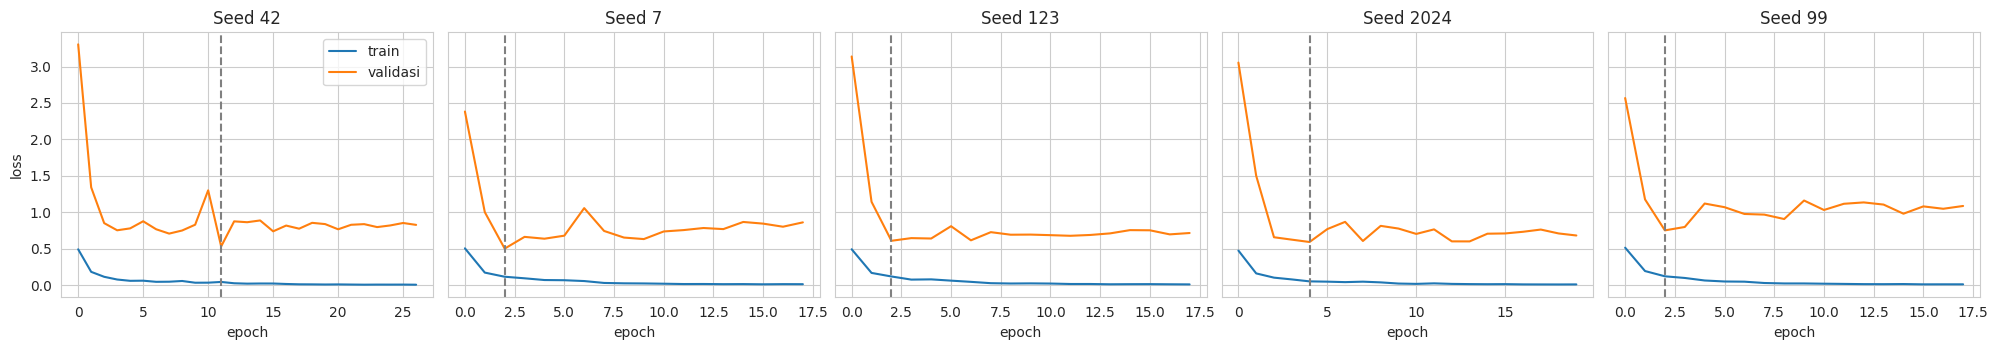

In [ ]:
fig, axes = plt.subplots(1, len(SEEDS), figsize=(20, 3.6), sharey=True)
for ax, seed in zip(axes, SEEDS):
    hh = riwayat_cnn[seed]
    ax.plot(hh["loss"], label="train")
    ax.plot(hh["val_loss"], label="validasi")
    ax.axvline(np.argmin(hh["val_loss"]), ls="--", c="gray")
    ax.set_title(f"Seed {seed}")
    ax.set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"{HASIL}/kurva_loss_cnn_5seed.png", dpi=150)
plt.show()

### 14.6 Kinerja per Kelas

#### 14.6.1 F1 per kelas ketiga model (rata-rata ± simpangan baku, 5 seed)


In [ ]:
f1_cnn = pd.DataFrame([f1_score(y_test, p, average=None) for p in prediksi_cnn.values()],
                      index=SEEDS, columns=kelas)
tabel_kelas["1D-CNN"] = f1_cnn.apply(mean_std)
display(tabel_kelas)
tabel_kelas.to_csv(f"{HASIL}/f1_per_kelas_semua_model.csv")

,SVM,RF,1D-CNN
Downstairs,0.7980 ± 0.0000,0.8190 ± 0.0065,0.7201 ± 0.0992
Jogging,0.9174 ± 0.0000,0.9478 ± 0.0011,0.9461 ± 0.0475
Sitting,0.8730 ± 0.0000,0.7709 ± 0.0567,0.8410 ± 0.0853
Standing,0.8770 ± 0.0000,0.8061 ± 0.0315,0.8516 ± 0.0490
Upstairs,0.6500 ± 0.0000,0.7169 ± 0.0230,0.5821 ± 0.0778
Walking,0.9215 ± 0.0000,0.9547 ± 0.0055,0.8956 ± 0.0593


#### 14.6.2 Classification report dan confusion matrix CNN (seed 42)


              precision    recall  f1-score   support

  Downstairs     0.7243    0.8934    0.8000       197
     Jogging     0.9317    1.0000    0.9647       696
     Sitting     1.0000    0.7857    0.8800       140
    Standing     0.7698    1.0000    0.8699       107
    Upstairs     0.6298    0.7583    0.6881       240
     Walking     0.9939    0.8410    0.9110       962

    accuracy                         0.8881      2342
   macro avg     0.8416    0.8797    0.8523      2342
weighted avg     0.9055    0.8881    0.8911      2342



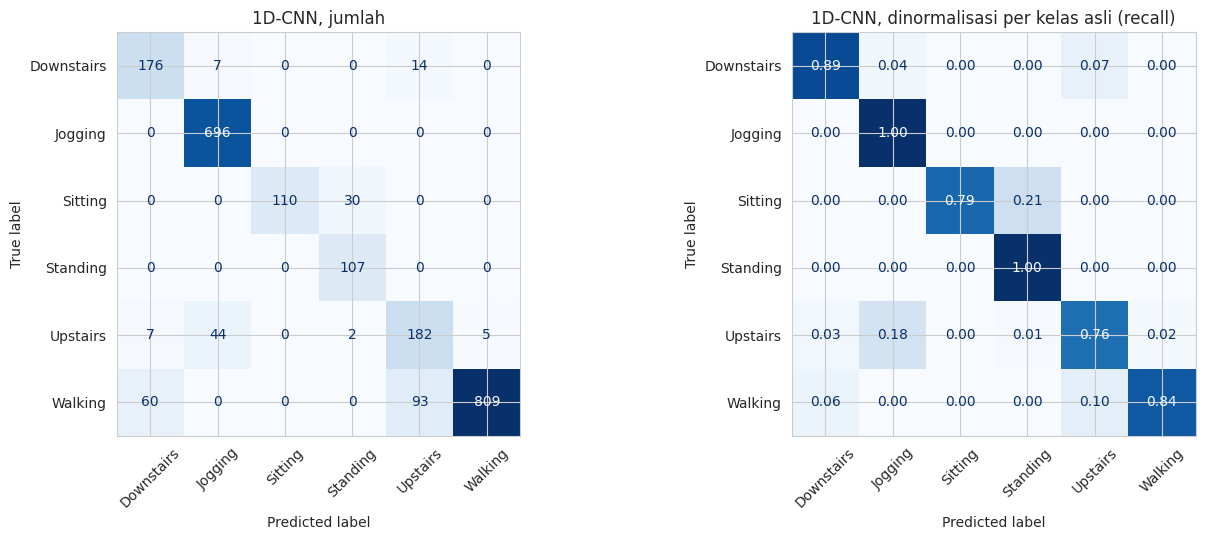

In [ ]:
tampilkan_cm(prediksi_cnn[42], "1D-CNN", "CNN")

#### 14.6.3 Prediksi jendela Sitting per subjek test (seed 42)


In [ ]:
display(prediksi_per_subjek(prediksi_cnn[42], "Sitting"))

Prediksi,Sitting,Standing
Subjek,,
12,32,0
16,42,0
19,36,0
27,0,30


### 14.7 Hasil evaluasi dan kinerja per kelas

Pada data test dengan 5 seed, 1D-CNN (varian D) mencapai accuracy 0,8511 ± 0,0518 dan macro-F1 0,8061 ± 0,0567. Waktu latihnya 48,32 ± 11,89 detik di GPU, dan waktu inferensinya 0,243 ± 0,008 ms per sampel di CPU serta 0,065 ± 0,001 ms per sampel di GPU.

Rata-rata macro-F1 CNN lebih rendah daripada SVM (0,8395) dan Random Forest (0,8359), tetapi variasinya jauh lebih besar. Macro-F1 test per seed berkisar antara 0,7138 dan 0,8523. Dua seed terbaik (42 dengan 0,8523 dan 7 dengan 0,8516) melampaui kedua model tradisional, sedangkan seed terburuk (123 dengan 0,7138) jauh di bawahnya. Simpangan baku CNN (0,057) lebih dari tiga kali lipat Random Forest (0,018), sementara SVM deterministik. Jadi tidak ada bukti bahwa CNN lebih baik atau lebih buruk secara rata-rata, tetapi CNN jelas paling tidak konsisten.

Overfitting terlihat jelas pada kurva loss. Loss train turun mendekati 0, sedangkan val_loss mencapai titik terendah pada epoch 3 sampai 12, lalu berfluktuasi atau naik. Pada seed 99 misalnya, val_loss naik dari sekitar 0,75 menjadi sekitar 1,1. Macro-F1 turun dari 0,964 di train menjadi 0,845 di validasi dan 0,806 di test. Early stopping membatasi overfitting dengan mengembalikan bobot terbaik, tetapi tidak menghilangkan selisih generalisasi antarsubjek.

Upstairs adalah kelas tersulit pada CNN, dengan F1 0,582 ± 0,078, disusul Downstairs (0,720 ± 0,099). Pada seed 42, 76% jendela Upstairs dikenali benar dan 18% diprediksi sebagai Jogging, sedangkan 10% jendela Walking (93 jendela) diprediksi sebagai Upstairs, sehingga presisi Upstairs hanya 0,63. Seed 42 merupakan seed CNN terbaik, sehingga kesalahannya lebih sedikit dibanding rata-rata kelima seed. Simpangan baku F1 CNN lebih besar daripada Random Forest pada semua kelas, terutama Downstairs (± 0,099) dan Sitting (± 0,085), sehingga kemampuan CNN mengenali kelas tertentu sangat bergantung pada inisialisasi bobot dan urutan data saat pelatihan.

Kesalahan Sitting ke Standing pada subjek 27 juga terjadi pada CNN, dengan 30 dari 30 jendela salah, sedangkan subjek 12, 16, dan 19 dikenali dengan benar seluruhnya. Karena ketiga model gagal pada subjek yang sama, penyebabnya lebih mungkin keterbatasan informasi di dalam data, yaitu orientasi ponsel (bagian 13.5), bukan kelemahan metode tertentu.

CNN tidak memerlukan ekstraksi fitur. Waktu inferensinya di CPU (0,243 ms per sampel) sedikit lebih lambat daripada SVM (0,227 ms) dan jauh lebih lambat daripada Random Forest (0,089 ms). Pelatihan CNN di GPU (48,3 detik) lebih lama daripada SVM (0,87 detik) dan Random Forest (21,2 detik) yang dilatih di CPU, sehingga perbandingan waktu latih ini tidak menggunakan perangkat yang setara dan dicatat sebagai keterbatasan.

## 15. Rekapitulasi Hasil



### 15.1 Tabel Hasil Utama

Nilai pada tabel adalah rata-rata ± simpangan baku dari 5 seed pada data test. Waktu inferensi per sampel diukur di CPU untuk ketiga model agar setara, dan untuk pendekatan tradisional sudah termasuk waktu ekstraksi fitur.

#### 15.1.1 Tabel hasil utama

In [ ]:
baris = []
for label, kode in [("Tradisional 1 (SVM)", "SVM"), ("Tradisional 2 (Random Forest)", "RF")]:
    d = per_seed[per_seed.Model == kode]
    baris.append({"Model": label, "Representasi masukan": "Fitur manual (79 fitur)",
                  "Accuracy": mean_std(d["Accuracy test"]), "Macro-F1": mean_std(d["Macro-F1 test"]),
                  "Waktu pelatihan (s)": mean_std(d["Waktu latih (s)"], 2),
                  "Waktu inferensi per sampel (ms)": mean_std(d["Inferensi total (ms/sampel)"]),
                  "Perangkat pelatihan": f"CPU ({multiprocessing.cpu_count()} core)"})
baris.append({"Model": "Deep learning (1D-CNN)", "Representasi masukan": "Segmen sinyal (128 × 3)",
              "Accuracy": mean_std(cnn_df["Accuracy test"]), "Macro-F1": mean_std(cnn_df["Macro-F1 test"]),
              "Waktu pelatihan (s)": mean_std(cnn_df["Waktu latih (s)"], 2),
              "Waktu inferensi per sampel (ms)": mean_std(cnn_df["Inferensi CPU (ms/sampel)"]),
              "Perangkat pelatihan": f"GPU ({NAMA_GPU})" if NAMA_GPU else "CPU"})

tabel_hasil = pd.DataFrame(baris).set_index("Model")
display(tabel_hasil)

,Representasi masukan,Accuracy,Macro-F1,Waktu pelatihan (s),Waktu inferensi per sampel (ms),Perangkat pelatihan
Model,,,,,,
Tradisional 1 (SVM),Fitur manual (79 fitur),0.8745 ± 0.0000,0.8395 ± 0.0000,0.87 ± 0.02,0.2267 ± 0.0089,CPU (2 core)
Tradisional 2 (Random Forest),Fitur manual (79 fitur),0.9031 ± 0.0081,0.8359 ± 0.0179,21.19 ± 2.50,0.0888 ± 0.0003,CPU (2 core)
Deep learning (1D-CNN),Segmen sinyal (128 × 3),0.8511 ± 0.0518,0.8061 ± 0.0567,48.32 ± 11.89,0.2429 ± 0.0079,GPU (Tesla T4)


#### 15.1.2 Simpan rekap hasil (CSV dan XLSX)

In [ ]:
semua_pred = {("SVM", s): prediksi[("SVM", s)] for s in SEEDS}
semua_pred.update({("RF", s): prediksi[("RF", s)] for s in SEEDS})
semua_pred.update({("1D-CNN", s): prediksi_cnn[s] for s in SEEDS})

baris_pk = []
for (model, seed), pred in semua_pred.items():
    p, r, f, n = precision_recall_fscore_support(y_test, pred, labels=range(len(kelas)), zero_division=0)
    for i, k in enumerate(kelas):
        baris_pk.append({"Model": model, "Seed": seed, "Kelas": k,
                         "Precision": p[i], "Recall": r[i], "F1": f[i], "Support": n[i]})

per_kelas_seed = pd.DataFrame(baris_pk)
tabel_pk = (per_kelas_seed.groupby(["Model", "Kelas"], sort=False)[["Precision", "Recall", "F1"]]
            .agg(mean_std).unstack("Model"))
tabel_pk = tabel_pk.reindex(columns=["SVM", "RF", "1D-CNN"], level=1).loc[urutan]
display(tabel_pk)

per_kelas_seed.to_csv(f"{HASIL}/per_kelas_per_seed.csv", index=False)
tabel_pk.to_csv(f"{HASIL}/precision_recall_f1_per_kelas.csv")
with pd.ExcelWriter(f"{HASIL}/rekap_hasil.xlsx", mode="a", engine="openpyxl", if_sheet_exists="replace") as w:
    tabel_pk.to_excel(w, sheet_name="Precision Recall F1")

Precision                                    \
Model                   SVM               RF           1D-CNN   
activity                                                        
Walking     0.9916 ± 0.0000  0.9492 ± 0.0014  0.9913 ± 0.0103   
Jogging     0.8739 ± 0.0000  0.9009 ± 0.0020  0.9541 ± 0.0253   
Upstairs    0.6036 ± 0.0000  0.8174 ± 0.0516  0.5536 ± 0.0992   
Downstairs  0.7751 ± 0.0000  0.9108 ± 0.0132  0.6074 ± 0.1312   
Sitting     0.9821 ± 0.0000  1.0000 ± 0.0000  0.9955 ± 0.0063   
Standing    0.7810 ± 0.0000  0.6761 ± 0.0441  0.7440 ± 0.0704   

                     Recall                                    \
Model                   SVM               RF           1D-CNN   
activity                                                        
Walking     0.8607 ± 0.0000  0.9603 ± 0.0110  0.8214 ± 0.0965   
Jogging     0.9655 ± 0.0000  1.0000 ± 0.0000  0.9448 ± 0.1012   
Upstairs    0.7042 ± 0.0000  0.6392 ± 0.0096  0.6500 ± 0.1753   
Downstairs  0.8223 ± 0.0000  0.7442 ± 0.0111  0.9117 ± 0.0640   
Sitting     0.7857 ± 0.0000  0.6300 ± 0.0745  0.7343 ± 0.1150   
Standing    1.0000 ± 0.0000  1.0000 ± 0.0000  1.0000 ± 0.0000   

                         F1                                    
Model                   SVM               RF           1D-CNN  
activity                                                       
Walking     0.9215 ± 0.0000  0.9547 ± 0.0055  0.8956 ± 0.0593  
Jogging     0.9174 ± 0.0000  0.9478 ± 0.0011  0.9461 ± 0.0475  
Upstairs    0.6500 ± 0.0000  0.7169 ± 0.0230  0.5821 ± 0.0778  
Downstairs  0.7980 ± 0.0000  0.8190 ± 0.0065  0.7201 ± 0.0992  
Sitting     0.8730 ± 0.0000  0.7709 ± 0.0567  0.8410 ± 0.0853  
Standing    0.8770 ± 0.0000  0.8061 ± 0.0315  0.8516 ± 0.0490

Selesai, sheet 'Precision Recall F1' ditambahkan


#### 15.1.3 Hasil

| Model | Representasi masukan | Accuracy | Macro-F1 | Waktu pelatihan (s) | Waktu inferensi per sampel (ms) | Perangkat pelatihan |
|---|---|---|---|---|---|---|
| Tradisional 1 (SVM) | Fitur manual (79 fitur) | 0,8745 ± 0,0000 | 0,8395 ± 0,0000 | 0,87 ± 0,02 | 0,2267 ± 0,0089 | CPU (2 core) |
| Tradisional 2 (Random Forest) | Fitur manual (79 fitur) | 0,9031 ± 0,0081 | 0,8359 ± 0,0179 | 21,19 ± 2,50 | 0,0888 ± 0,0003 | CPU (2 core) |
| Deep learning (1D-CNN) | Segmen sinyal (128 × 3) | 0,8511 ± 0,0518 | 0,8061 ± 0,0567 | 48,32 ± 11,89 | 0,2429 ± 0,0079 | GPU (Tesla T4) |

Data test terdiri atas 6 subjek dan 2.342 jendela. Waktu inferensi diukur di CPU untuk ketiga model, dan untuk model tradisional sudah termasuk ekstraksi fitur. Seluruh tabel hasil, termasuk hasil per seed, precision, recall, dan F1 per kelas, pengaruh kelompok fitur, dan proses pemilihan model, tersimpan di `hasil/rekap_hasil.xlsx`.

### 15.2 Analisis Kesalahan Upstairs

Bagian ini memeriksa apakah kesalahan pada kelas Upstairs, terutama Upstairs ke Standing pada CNN, terkonsentrasi pada subjek test tertentu.

#### 15.2.1 Prediksi jendela Upstairs per subjek test (seed 42)


In [ ]:
for nama, p in [("SVM", prediksi[("SVM", 42)]), ("RF", prediksi[("RF", 42)]), ("1D-CNN", prediksi_cnn[42])]:
    print(nama)
    display(prediksi_per_subjek(p, "Upstairs"))

SVM


Prediksi,Downstairs,Jogging,Sitting,Upstairs,Walking
Subjek,,,,,
12,1,5,0,26,1
15,0,0,0,15,0
16,1,0,0,15,0
19,1,5,1,50,4
22,17,0,1,60,0
27,2,32,0,3,0


RF


Prediksi,Downstairs,Jogging,Upstairs,Walking
Subjek,,,,
12,1,18,13,1
15,1,0,6,8
16,2,0,14,0
19,1,5,42,13
22,0,0,78,0
27,0,37,0,0


1D-CNN


Prediksi,Downstairs,Jogging,Standing,Upstairs,Walking
Subjek,,,,,
12,1,8,0,24,0
15,0,0,0,15,0
16,0,0,0,16,0
19,6,0,0,50,5
22,0,0,2,76,0
27,0,36,0,1,0


#### 15.2.2 Intensitas dan orientasi Upstairs per subjek test dibanding rata-rata train


In [ ]:
kol_up = ["x_mean", "y_mean", "z_mean", "mag_std", "mag_dom_freq"]
m_test, m_train = y_test_txt == "Upstairs", y_train_txt == "Upstairs"

print("Upstairs per subjek test")
display(F_test.loc[m_test, kol_up].groupby(g_test[m_test]).mean().round(2))
print("Upstairs rata-rata train")
display(F_train.loc[m_train, kol_up].mean().round(2).to_frame("mean").T)

Upstairs per subjek test


,x_mean,y_mean,z_mean,mag_std,mag_dom_freq
12,-1.36,8.32,2.49,4.96,1.81
15,-3.82,8.97,-0.29,4.94,1.90
16,2.74,9.87,-0.99,4.17,2.18
19,-4.40,4.56,-0.39,5.04,2.01
22,-2.30,9.11,-1.64,2.55,1.51
27,-1.36,-0.13,0.37,7.91,2.85


Upstairs rata-rata train


,x_mean,y_mean,z_mean,mag_std,mag_dom_freq
mean,1.0,8.34,0.25,3.91,1.92


#### 15.2.3 Hasil analisis kesalahan pada kelas Upstairs

Kesalahan pada kelas Upstairs terkonsentrasi pada subjek tertentu. Subjek 12, 15, 16, dan 19 sebagian besar dikenali dengan benar oleh ketiga model.

Jendela Upstairs milik subjek 27 hampir seluruhnya diprediksi sebagai Jogging oleh ketiga model, yaitu 32 dari 37 jendela pada SVM, 37 dari 37 pada Random Forest, dan 36 dari 37 pada CNN. Fitur Upstairs subjek ini memang menyerupai Jogging. Intensitasnya (mag_std 7,91) dua kali lipat rata-rata Upstairs di train (3,91) dan bahkan lebih tinggi daripada rata-rata Jogging di train (6,51). Frekuensi dominannya 2,85 Hz, mendekati Jogging (3,05 Hz) dan jauh di atas Upstairs di train (1,92 Hz). Dugaannya, subjek 27 menaiki tangga dengan sangat cepat atau setengah berlari. Mean ketiga sumbunya juga mendekati nol (x = −1,36, y = −0,13, z = 0,37), berbeda dari pola umum di mana gravitasi dominan di sumbu y (sekitar 8,3), yang menunjukkan posisi atau pergerakan ponsel yang tidak lazim. Subjek 27 juga merupakan sumber seluruh kesalahan Sitting ke Standing (bagian 13.5), sehingga subjek ini secara umum atipikal.

Subjek 22 menaiki tangga dengan intensitas paling rendah (mag_std 2,55, dibanding 3,91 di train) dan ritme paling lambat (1,51 Hz, dibanding 1,92 Hz di train). Pada subjek ini, SVM salah pada 18 dari 78 jendela, sebagian besar ke Downstairs (17 jendela), sedangkan Random Forest benar seluruhnya dan CNN benar pada 76 dari 78 jendela.

Secara keseluruhan, sebagian besar kesalahan di test berasal dari variasi gaya gerak dan posisi ponsel antarsubjek, terutama dari subjek 27. Dengan hanya 6 subjek di test, peringkat antarmodel sangat dipengaruhi oleh subjek mana yang kebetulan masuk ke test, dan hal ini dicatat sebagai keterbatasan utama.

## 16. Pembahasan

### 16.1 Pendekatan mana yang menghasilkan macro-F1 tertinggi, dan seberapa konsisten hasilnya?

SVM memiliki rata-rata macro-F1 tertinggi (0,8395), diikuti Random Forest (0,8359 ± 0,0179) dan 1D-CNN (0,8061 ± 0,0567). Namun selisih rata-ratanya, yaitu 0,004 dan 0,033, lebih kecil daripada simpangan baku RF dan CNN, sehingga tidak ada pendekatan yang terbukti unggul. Dari sisi konsistensi, SVM paling stabil karena bersifat deterministik, RF cukup stabil dengan rentang 0,8089 sampai 0,8545, dan CNN paling tidak konsisten dengan rentang 0,7138 sampai 0,8523. Seed terbaik CNN melampaui model tradisional, tetapi seed terburuknya jauh di bawahnya. Simpangan baku ini hanya mencerminkan keacakan pelatihan, bukan ketidakpastian akibat pemilihan 6 subjek test. Accuracy RF (0,9031) lebih tinggi daripada SVM (0,8745) karena RF lebih baik pada kelas mayoritas, tetapi perbedaan ini hilang pada macro-F1 yang memberi bobot sama bagi setiap kelas.

### 16.2 Kelas apa yang paling sulit dikenali, dan bagaimana karakteristik sinyalnya menjelaskan kesalahan tersebut?

Upstairs adalah kelas tersulit pada ketiga model, karena statistik domain waktunya mirip Walking dan Downstairs (bagian 8.3) dan frekuensi dominannya (1,92 Hz) hanya berselisih sekitar 0,3 Hz dari Walking. Namun kesalahan terbesar berasal dari variasi gaya gerak antarsubjek, seperti subjek 27 yang menaiki tangga dengan intensitas dan ritme setara Jogging (bagian 15.2). Sitting dan Standing hanya dibedakan oleh arah gravitasi relatif terhadap ponsel. Karena subjek 27 meletakkan ponsel dengan orientasi yang sama seperti saat berdiri, ketiga model gagal 100% pada subjek ini. Masalah ini lebih tepat dipandang sebagai keterbatasan informasi pada data, bukan kelemahan metode tertentu. Kelemahan utama CNN adalah ketidakstabilan antarseed, yang juga terlihat pada simpangan baku F1 per kelas yang lebih besar daripada Random Forest pada semua kelas.

### 16.3 Bagaimana penambahan kelompok fitur memengaruhi kinerja metode tradisional?

Menggabungkan fitur domain waktu dan frekuensi memberi peningkatan terbesar. Dibanding fitur waktu saja, macro-F1 test naik dari 0,7417 menjadi 0,8137 pada SVM (naik 0,072) dan dari 0,7242 menjadi 0,8221 pada Random Forest (naik 0,098). Fitur waktu menangkap orientasi dan intensitas, sedangkan fitur frekuensi menangkap ritme, sehingga keduanya saling melengkapi. Fitur frekuensi saja bahkan lebih baik daripada fitur waktu saja di test, dan penurunannya dari validasi ke test lebih kecil, kemungkinan karena sebagian besar fitur frekuensi tidak bergantung pada orientasi ponsel. Penambahan 3 fitur korelasi antarsumbu hanya memberi dampak kecil.

### 16.4 Apakah terdapat indikasi overfitting pada model deep learning?

Ya. Loss train turun mendekati 0, sementara val_loss mencapai titik terendah pada epoch 3 sampai 12 lalu berfluktuasi atau naik, dan macro-F1 turun dari 0,964 di train menjadi 0,845 di validasi dan 0,806 di test. Early stopping membatasi dampaknya, tetapi augmentasi, regularisasi L2, dan dropout tambahan tidak memperbaiki macro-F1 validasi secara bermakna (bagian 14.4). Pola serupa juga tampak pada model tradisional (macro-F1 train sekitar 0,99 sampai 1,00 dan validasi 0,88 sampai 0,91), sehingga selisih ini terutama disebabkan oleh perbedaan antarsubjek, bukan semata kapasitas model yang berlebih.

### 16.5 Bagaimana perbandingan kebutuhan waktu komputasi kedua pendekatan?

SVM sekitar 24 kali lebih cepat dilatih daripada RF dan sekitar 56 kali lebih cepat daripada CNN, sedangkan pemilihan model CNN membutuhkan 12 kali pelatihan tambahan. Untuk inferensi di CPU, RF paling cepat (0,089 ms per sampel, termasuk ekstraksi fitur 0,047 ms), disusul SVM (0,227 ms) dan CNN (0,243 ms). Di GPU, inferensi CNN 0,065 ms per sampel. Karena jendela baru muncul setiap 3,2 detik, ketiga model jauh lebih cepat daripada kebutuhan waktu nyata. Waktu yang terukur bervariasi antarrun karena Colab menggunakan server bersama, dan perbandingan waktu latih tidak setara karena perangkatnya berbeda (CPU dan GPU).

### 16.6 Apakah peningkatan kinerja sebanding dengan kompleksitas model?

Pada dataset ini, kompleksitas tambahan tidak diikuti peningkatan kinerja yang sepadan. 1D-CNN memiliki 97.862 parameter, membutuhkan GPU, dan waktu latihnya sekitar 56 kali SVM, tetapi rata-rata macro-F1-nya justru paling rendah (0,8061) dengan variasi antarseed terbesar. Random Forest membutuhkan waktu latih sekitar 24 kali SVM tanpa kenaikan macro-F1. Fitur manual berbasis orientasi, intensitas, dan ritme gerakan sudah menangkap informasi utama, meskipun dua seed terbaik CNN (0,8523 dan 0,8516) menunjukkan bahwa deep learning berpotensi unggul pada data dengan subjek yang lebih banyak.

### 16.7 Pendekatan apa yang direkomendasikan, dan apa batas keberlakuan rekomendasinya?

SVM dengan kernel RBF dan gabungan fitur waktu, frekuensi, dan antarsumbu direkomendasikan karena memiliki macro-F1 rata-rata tertinggi, hasilnya deterministik, pelatihannya paling cepat tanpa GPU, dan inferensinya cukup untuk penggunaan waktu nyata. Random Forest menjadi alternatif jika kecepatan inferensi lebih diutamakan. Rekomendasi ini terbatas pada satu akselerometer smartphone di saku, enam aktivitas WISDM, dan 36 subjek dalam kondisi terkontrol. Karena data test hanya berisi 6 subjek dan selisih antarmodel lebih kecil daripada variasi antarseed, rekomendasi ini didasarkan pada keseimbangan kinerja, konsistensi, dan biaya komputasi, bukan keunggulan akurasi yang meyakinkan.